<a href="https://colab.research.google.com/github/rzjuliannofficial/PCVK_18_Julian/blob/main/PCVK_W10_2341720255_Nabhan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 10 – Praktikum Dasar-Dasar Deteksi Obyek


# D1. Praktikum Deteksi Obyek Dasar

## Percobaan 1 – Menyiapkan Notebook, Library, dan Akses Drive


In [ ]:
#import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
# akses drive (Colab) atau folder lokal
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PATH = '/content/drive/MyDrive/Kuliah/Semester5/PCVK/Img'
    if not os.path.isdir(PATH):
        raise FileNotFoundError
except Exception:
    # dijalankan lokal: pakai folder Img di samping notebook
    PATH = os.path.abspath('Img')
    print('Mode lokal. PATH =', PATH)


Mode lokal. PATH = c:\KULIAH\1.Teknik Informatika Kuliah\Semester 5\PCVK(Pengolaan Citra dan Visi Komputer)\week10\Img


In [ ]:
import os

# PATH sudah di-set pada sel sebelumnya (Google Drive saat di Colab, folder Img saat lokal)
PATH_FACE = PATH                        # gambar face detection ada di folder Img
PATH_CASCADE = cv.data.haarcascades     # file XML pretrained Haar Cascade bawaan OpenCV

print('PATH        :', PATH)
print('PATH_FACE   :', PATH_FACE)
print('PATH_CASCADE:', PATH_CASCADE)


PATH        : c:\KULIAH\1.Teknik Informatika Kuliah\Semester 5\PCVK(Pengolaan Citra dan Visi Komputer)\week10\Img
PATH_FACE   : c:\KULIAH\1.Teknik Informatika Kuliah\Semester 5\PCVK(Pengolaan Citra dan Visi Komputer)\week10\Img
PATH_CASCADE: c:\Users\lianb\anaconda3\Lib\site-packages\cv2\data\


**Kesimpulan**
Library dan Drive siap dipakai. Semua gambar dibaca lewat `PATH`, `PATH_FACE`, dan `PATH_CASCADE`, jadi jika folder pindah cukup mengubah variabel di sel ini.

## Percobaan 2 – Template Matching dengan 6 Metode OpenCV
**Penjelasan**
- **Template matching** mencari lokasi gambar template (`cat2_template.jpg`) pada gambar yang lebih besar (`cats_and_bunnies.jpg`) dengan menggeser template dari kiri ke kanan dan atas ke bawah, lalu menghitung skor kecocokan di setiap posisi. Skor disimpan dalam matriks hasil `R`.
- Fungsinya `cv.matchTemplate(image, templ, method)`; ukuran template tidak boleh lebih besar dari gambar input.
- Enam metode: `TM_SQDIFF`, `TM_SQDIFF_NORMED`, `TM_CCORR`, `TM_CCORR_NORMED`, `TM_CCOEFF`, `TM_CCOEFF_NORMED`.
- Pada `TM_SQDIFF` dan `TM_SQDIFF_NORMED`, kecocokan terbaik adalah nilai **minimum**; pada empat metode lain adalah nilai **maksimum**.

**Pengerjaan**

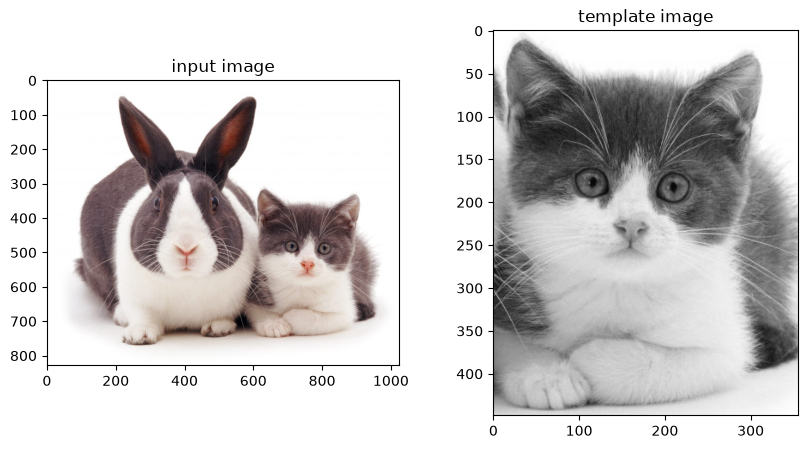

In [ ]:
img = cv.imread(f'{PATH}/cats_and_bunnies.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
template = cv.imread(f'{PATH}/cat2_templatejpg.jpg', 0)      # template dibaca grayscale
h, w = template.shape

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_rgb), plt.title('input image')
plt.subplot(122), plt.imshow(template, cmap='gray'), plt.title('template image')
plt.show()

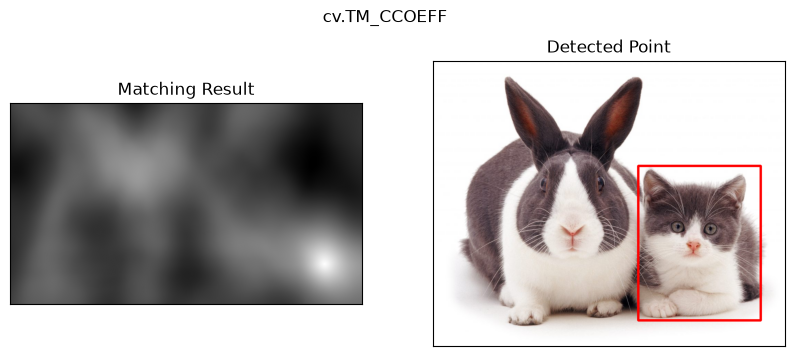

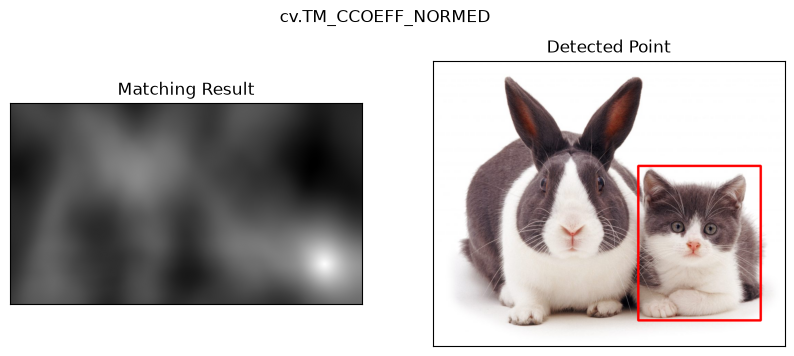

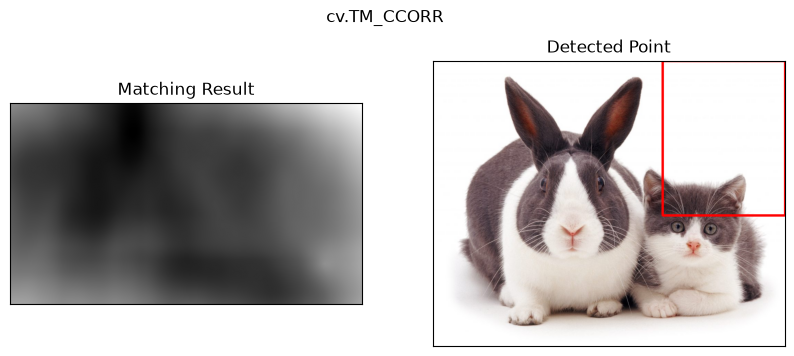

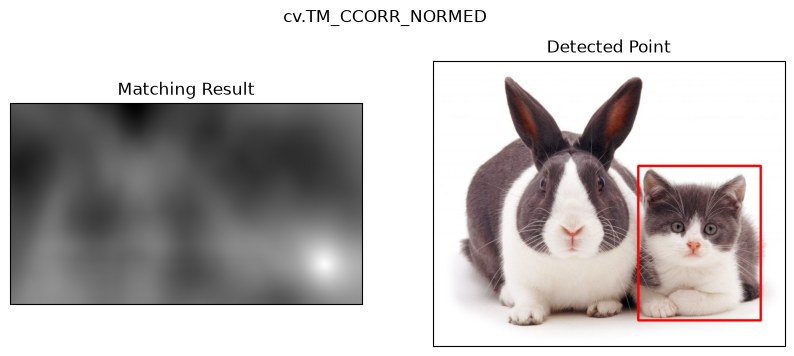

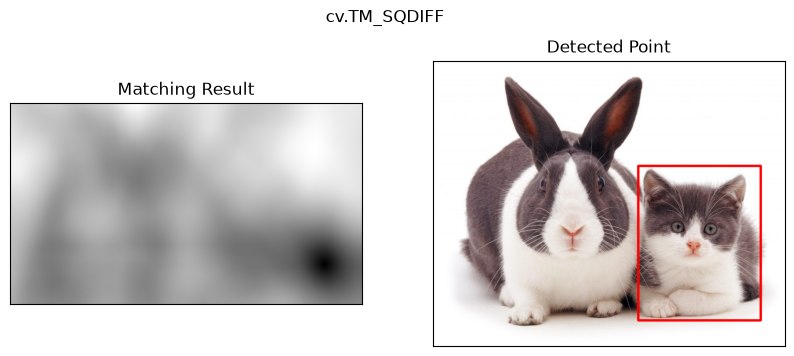

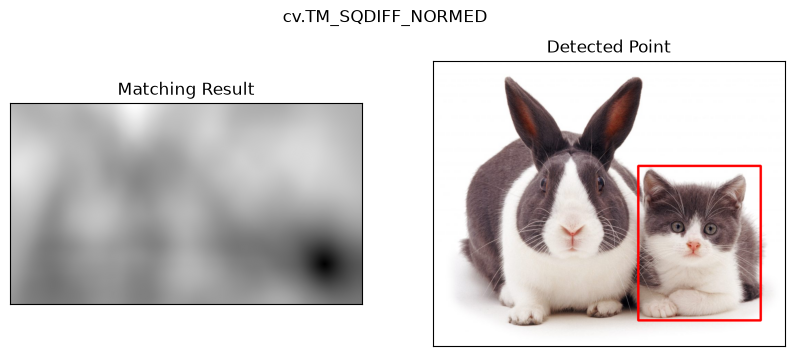

In [ ]:
# urutan metode sesuai contoh luaran modul
daftar_metode = [('cv.TM_CCOEFF', cv.TM_CCOEFF),
                 ('cv.TM_CCOEFF_NORMED', cv.TM_CCOEFF_NORMED),
                 ('cv.TM_CCORR', cv.TM_CCORR),
                 ('cv.TM_CCORR_NORMED', cv.TM_CCORR_NORMED),
                 ('cv.TM_SQDIFF', cv.TM_SQDIFF),
                 ('cv.TM_SQDIFF_NORMED', cv.TM_SQDIFF_NORMED)]

for nama_metode, method in daftar_metode:
    hasil = img_rgb.copy()

    # matriks hasil R
    res = cv.matchTemplate(img_gray, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    # SQDIFF: nilai terbaik = minimum, metode lain: maksimum
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)
    cv.rectangle(hasil, top_left, bottom_right, (255, 0, 0), 5)

    plt.figure(figsize=(10, 4))
    plt.suptitle(nama_metode)
    plt.subplot(121), plt.imshow(res, cmap='gray')
    plt.title('Matching Result'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(hasil)
    plt.title('Detected Point'), plt.xticks([]), plt.yticks([])
    plt.show()

**Kesimpulan / Analisis**
- Peta `Matching Result` yang **terang** menunjukkan kecocokan tinggi (untuk SQDIFF yang bagus justru titik **gelap**), dan kotak merah digambar pada lokasi terbaik.
- Pada contoh luaran modul, lima metode menemukan kucing dengan benar, sedangkan **`TM_CCORR` (tanpa normalisasi) salah lokasi** (kotak muncul di pojok kanan atas). Korelasi mentah cenderung besar di area yang terang, sehingga skornya tidak adil dibandingkan antar posisi.
- Metode berakhiran **`_NORMED`** dinormalisasi sehingga lebih tahan terhadap perbedaan kecerahan. Bandingkan keenam kotak di notebookmu dengan contoh luaran modul.

## Percobaan 3 – Template Matching TANPA Library OpenCV (Multiple Object)
**Penjelasan**
- Template (`bahrain-template.jpg`) digeser ke setiap posisi pada gambar (`bahrain.jpg`). Di tiap posisi dihitung **zero-mean normalized cross-correlation** (setara `TM_CCOEFF_NORMED`) dengan numpy, bukan `cv.matchTemplate`:
  `R = Σ(T−T̄)(I−Ī) / √(Σ(T−T̄)² · Σ(I−Ī)²)`. Nilainya antara −1 sampai 1.
- Karena objek yang dicari **lebih dari satu**, semua posisi dengan skor ≥ *threshold* dijadikan kandidat, lalu kandidat yang saling berdekatan disaring (hanya skor tertinggi yang disimpan) supaya satu objek hanya punya satu kotak.
- OpenCV hanya dipakai untuk membaca gambar; perhitungan kecocokan dan penggambaran kotak (kuning) dilakukan tanpa OpenCV.

**Pengerjaan**

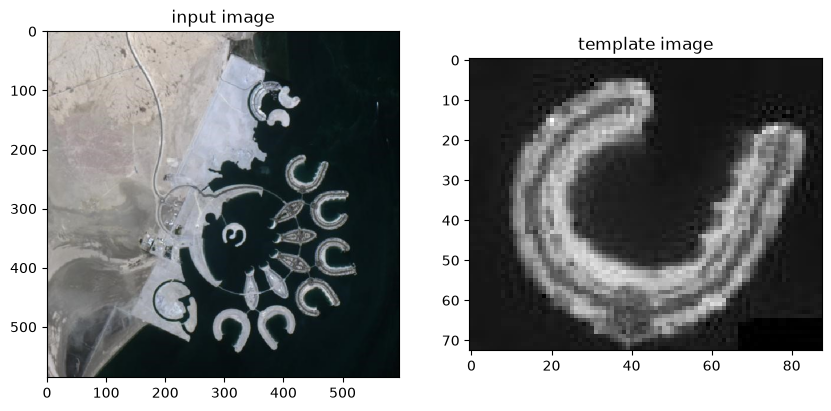

In [ ]:
from numpy.lib.stride_tricks import sliding_window_view
from matplotlib.patches import Rectangle

img = cv.imread(f'{PATH}/bahrain.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY).astype(np.float32)
template = cv.imread(f'{PATH}/bahrain-template.jpg', 0).astype(np.float32)
h, w = template.shape

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_rgb), plt.title('input image')
plt.subplot(122), plt.imshow(template, cmap='gray'), plt.title('template image')
plt.show()

In [ ]:
def template_matching(I, T):
    # zero-mean normalized cross-correlation (tanpa cv.matchTemplate)
    th, tw = T.shape
    H, W = I.shape
    T0 = T - T.mean()
    T_norm = np.sqrt((T0 ** 2).sum())
    R = np.zeros((H - th + 1, W - tw + 1), dtype=np.float32)
    for y in range(H - th + 1):
        strip = I[y:y + th, :]
        jendela = sliding_window_view(strip, (th, tw))[0]            # semua posisi x pada baris y
        J0 = jendela - jendela.mean(axis=(1, 2), keepdims=True)
        pembilang = (J0 * T0).sum(axis=(1, 2))
        penyebut = np.sqrt((J0 ** 2).sum(axis=(1, 2))) * T_norm
        R[y] = pembilang / (penyebut + 1e-8)
    return R

R = template_matching(gray, template)
print('Ukuran matriks R:', R.shape, '| skor maksimum:', round(float(R.max()), 3))

Ukuran matriks R: (514, 509) | skor maksimum: 0.964


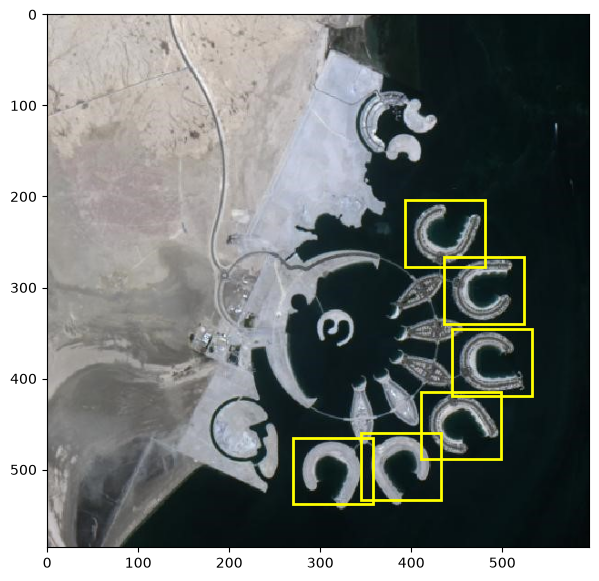

Jumlah objek terdeteksi: 6


In [ ]:
threshold = 0.45                                   # ubah jika objek terlewat / kotak berlebihan

kandidat = np.argwhere(R >= threshold)            # posisi (y, x) dengan skor di atas threshold
skor = R[kandidat[:, 0], kandidat[:, 1]]
urut = np.argsort(-skor)                          # skor tertinggi lebih dulu

kotak = []
for idx in urut:
    y, x = kandidat[idx]
    # simpan hanya jika tidak berdekatan dengan kotak yang sudah dipilih
    if all(abs(y - by) > h / 2 or abs(x - bx) > w / 2 for by, bx in kotak):
        kotak.append((y, x))

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(img_rgb)
for (y, x) in kotak:
    ax.add_patch(Rectangle((x, y), w, h, edgecolor='yellow', facecolor='none', linewidth=2))
plt.show()
print('Jumlah objek terdeteksi:', len(kotak))

**Kesimpulan / Analisis**
- Template digeser ke semua posisi, setiap posisi mendapat skor korelasi, lalu semua posisi bernilai tinggi disaring menjadi satu kotak per objek. Hasilnya berupa beberapa kotak kuning (jumlahnya tercetak di output).
- *Threshold* menentukan hasil: terlalu tinggi membuat objek terlewat, terlalu rendah memunculkan kotak yang salah.
- Template matching hanya cocok untuk objek yang **ukuran dan arahnya mirip template**. Karena itu objek yang berputar atau berbeda skala bisa tidak terdeteksi (pada contoh luaran modul, tidak semua bentuk "C" ikut terkotak).
- Hasil ini mengikuti konsep `TM_CCOEFF_NORMED` pada Percobaan 2, tetapi dihitung manual dengan loop dan numpy sehingga jauh lebih lambat daripada `cv.matchTemplate`.

## Percobaan 4 – Sobel, Canny, dan Laplacian Edge Detection (`car-park.jpg`)
**Penjelasan**
- **Edge detection** mencari piksel yang intensitasnya berubah tajam terhadap tetangganya, yaitu batas objek.
- **Sobel** menghitung gradien arah X dan Y dengan filter 3x3, lalu keduanya digabung.
- **Canny** menghaluskan citra dengan Gaussian, menghitung gradien, *non-maximum suppression*, lalu *hysteresis thresholding* (dua ambang).
- **Laplacian** memakai turunan kedua; sangat sensitif terhadap noise sehingga citra dihaluskan dengan Gaussian lebih dulu.

**Pengerjaan**

In [ ]:
img = cv.imread(f'{PATH}/car-park.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (5, 5), 0)         # penghalusan untuk Canny dan Laplacian

**a. Sobel Edge Detection**

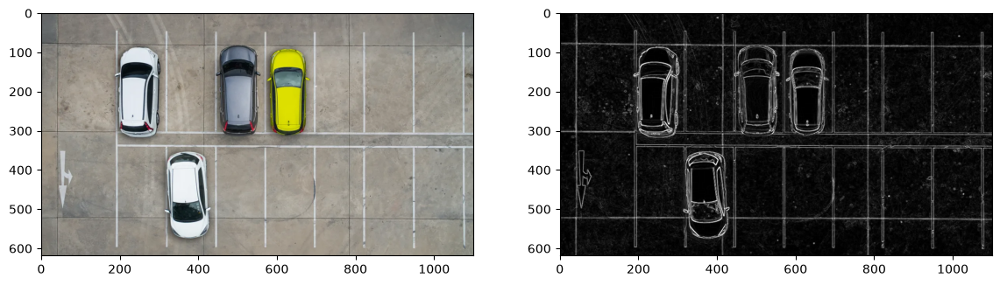

In [ ]:
sobel_x = cv.Sobel(gray, cv.CV_64F, 1, 0, ksize=3)     # gradien arah horizontal (Gx)
sobel_y = cv.Sobel(gray, cv.CV_64F, 0, 1, ksize=3)     # gradien arah vertikal (Gy)
abs_x = cv.convertScaleAbs(sobel_x)
abs_y = cv.convertScaleAbs(sobel_y)
sobel = cv.addWeighted(abs_x, 0.5, abs_y, 0.5, 0)      # gabungan X dan Y

plt.figure(figsize=(14, 5))
plt.subplot(121), plt.imshow(img_rgb)
plt.subplot(122), plt.imshow(sobel, cmap='gray')
plt.show()

**b. Canny Edge Detection**

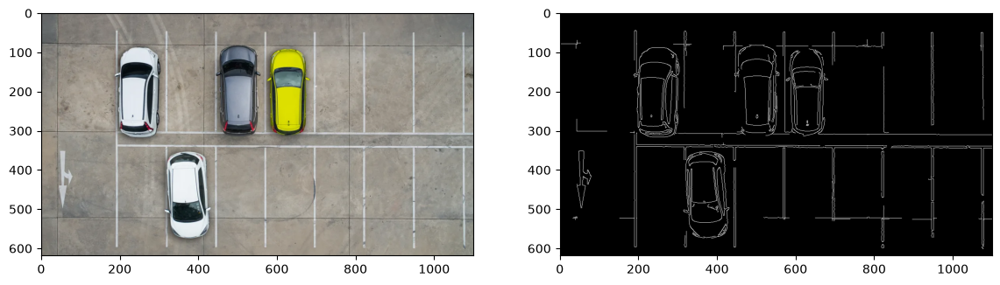

In [ ]:
canny = cv.Canny(blur, 100, 200)                       # ambang rendah 100, ambang tinggi 200

plt.figure(figsize=(14, 5))
plt.subplot(121), plt.imshow(img_rgb)
plt.subplot(122), plt.imshow(canny, cmap='gray')
plt.show()

**c. Laplacian Edge Detection**

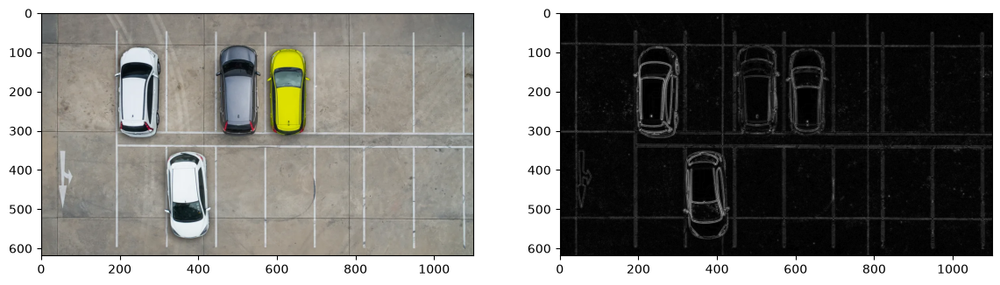

In [ ]:
laplacian = cv.Laplacian(blur, cv.CV_64F)
laplacian = cv.convertScaleAbs(laplacian)

plt.figure(figsize=(14, 5))
plt.subplot(121), plt.imshow(img_rgb)
plt.subplot(122), plt.imshow(laplacian, cmap='gray')
plt.show()

**Kesimpulan / Analisis**
- **Sobel:** menampilkan besar gradien, sehingga tepi kuat tampak terang dan tepi lemah (tekstur aspal) ikut terlihat samar. Garis tepinya relatif tebal.
- **Canny:** tepi berupa garis **tipis dan bersih** karena ada penghalusan, *non-maximum suppression*, dan *hysteresis*. Tepi yang lemah dan tidak tersambung dibuang. Pada contoh luaran modul, hasil Canny paling rapi.
- **Laplacian:** menandai tepi di semua arah sekaligus, tetapi paling sensitif terhadap noise (karena turunan kedua), sehingga penghalusan Gaussian sebelumnya penting.
- Pilihan metode bergantung kebutuhan: Canny untuk garis tepi yang jelas, Sobel jika arah gradien dibutuhkan, Laplacian untuk deteksi tepi cepat tanpa arah.

## Percobaan 5 – Harris Corner dan Shi-Tomasi Corner Detection (`chess-board.jpg`)
**Penjelasan**
- **Sudut (corner)** adalah titik persimpangan dua tepi, yaitu bagian citra yang intensitasnya berubah besar ke segala arah.
- **Harris:** `cv.cornerHarris(src, blockSize, ksize, k)` menghitung skor sudut `R = det(M) − k·(Tr(M))²` untuk tiap piksel; piksel dengan skor di atas ambang ditandai (merah).
- **Shi-Tomasi:** `cv.goodFeaturesToTrack(gray, jumlah, qualityLevel, minDistance)` menilai sudut dengan `R = min(λ1, λ2)` dan mengambil N sudut terkuat dengan jarak minimum antar sudut (biru). Citra input harus grayscale.

**Pengerjaan**

In [ ]:
img = cv.imread(f'{PATH}/chess-board.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

**a. Harris Corner Detection**

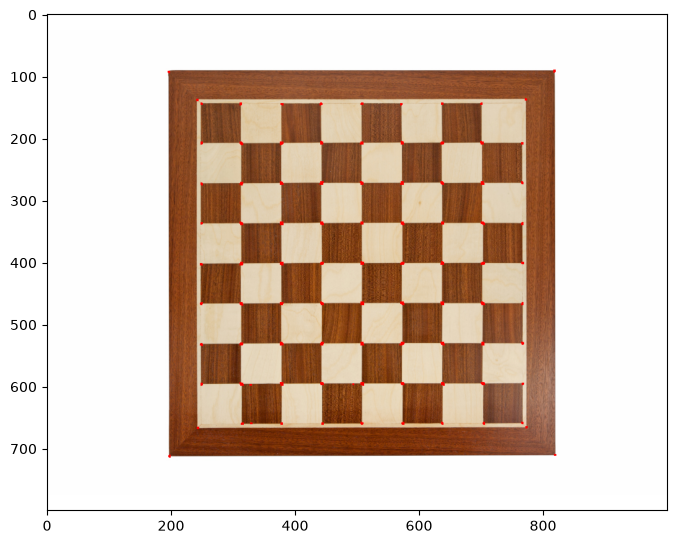

In [ ]:
gray32 = np.float32(gray)
dst = cv.cornerHarris(gray32, 2, 3, 0.04)          # blockSize=2, ksize=3, k=0.04
dst = cv.dilate(dst, None)                         # memperbesar titik agar mudah terlihat

hasil_harris = img_rgb.copy()
hasil_harris[dst > 0.01 * dst.max()] = [255, 0, 0] # tandai sudut dengan warna merah

plt.figure(figsize=(8, 8))
plt.imshow(hasil_harris)
plt.show()

**b. Shi-Tomasi Detection**

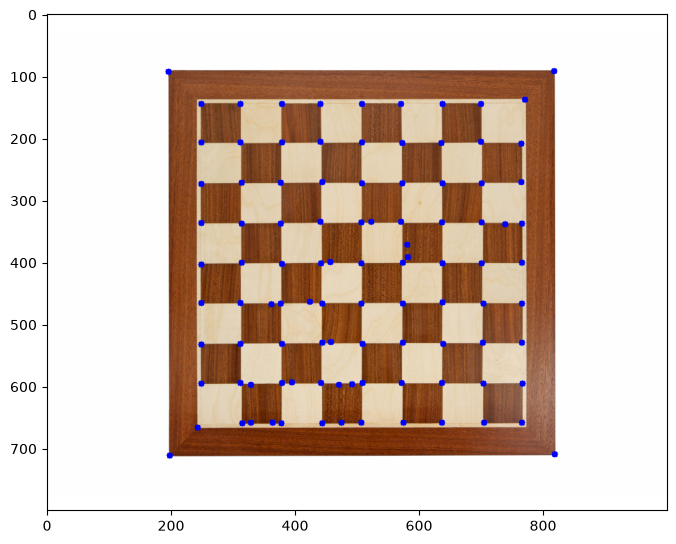

Jumlah sudut Shi-Tomasi: 100


In [ ]:
corners = cv.goodFeaturesToTrack(gray, 100, 0.01, 10)   # 100 sudut, kualitas min 0.01, jarak min 10 piksel
corners = np.int32(corners)

hasil_shi = img_rgb.copy()
for i in corners:
    x, y = i.ravel()
    cv.circle(hasil_shi, (x, y), 5, (0, 0, 255), -1)    # titik biru

plt.figure(figsize=(8, 8))
plt.imshow(hasil_shi)
plt.show()
print('Jumlah sudut Shi-Tomasi:', len(corners))

**Kesimpulan / Analisis**
- Kedua metode menandai **sudut kotak papan catur**, yaitu titik temu kotak terang dan gelap, serta sudut bingkai papan.
- **Harris** menandai semua piksel yang skornya di atas 1% dari skor maksimum, sehingga sudut tampak sebagai bercak merah di setiap persimpangan.
- **Shi-Tomasi** dibatasi jumlah (100) dan jarak minimum antar titik (10 piksel), sehingga hasilnya berupa titik-titik biru yang lebih terpisah. Jika sudut sah lebih banyak dari batas N, sebagian sudut tidak ikut tertandai; jika lebih sedikit, titik tambahan bisa muncul di tempat yang bukan sudut (seperti pada contoh luaran modul).

## Percobaan 6 – Grid Detection dengan Hough Transform (`sudoku.jpg`)
**Penjelasan**
Tahapan sesuai ulasan teori:
1. **Canny Edge Detection** untuk mendapat tepi.
2. **Dilasi** gambar tepi: Canny bisa menemukan dua tepi pada satu garis grid; dilasi menggabungkannya.
3. **Erosi**: setelah dilasi garis menjadi tebal, sehingga Hough akan mendeteksi banyak garis; erosi menipiskannya.
4. **`cv.HoughLines()`** mendeteksi garis dalam bentuk `(rho, theta)`.
5. **Menggabungkan garis yang mirip** (nilai `rho` dan `theta` berdekatan) menjadi satu garis.

**Pengerjaan**

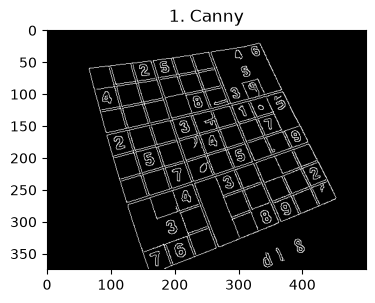

In [ ]:
img = cv.imread(f'{PATH}/sudoku.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

img_blur = cv.GaussianBlur(gray, (5,5), 0)

# 1. Canny Edge Detection (Sesuaikan threshold bawah dan atas)
edges = cv.Canny(img_blur, 30, 200, apertureSize=3)


plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(edges, cmap='gray'), plt.title('1. Canny')
plt.show()

In [ ]:
# 4. HoughLines (threshold = jumlah suara minimum; disesuaikan menjadi 200 agar lebih bersih)
lines = cv.HoughLines(edges, 1, np.pi / 180, 90)
print('Jumlah garis hasil HoughLines:', 0 if lines is None else len(lines))

Jumlah garis hasil HoughLines: 95


Jumlah garis setelah digabung: 20


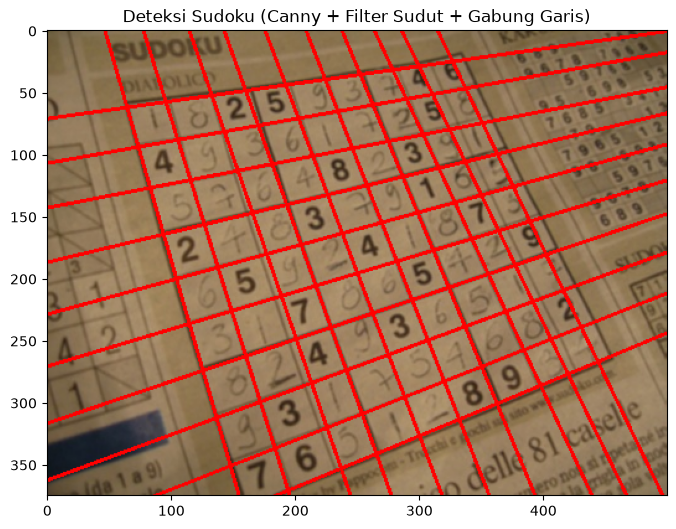

In [ ]:
# 5. Modifikasi fungsi untuk memperbaiki syntax error DAN menyaring garis diagonal
def gabung_garis(lines, selisih_rho=20, selisih_theta=np.pi / 18):
    if lines is None:
        return []
    kelompok = []

    for rho, theta in lines[:, 0]:
        # Filter sudut: Buang garis diagonal (pertahankan yang mendekati 0, 90, 180 derajat)
        deg = np.rad2deg(theta)
        is_vertical = (deg < 20) or (deg > 120)
        is_horizontal = (60 < deg < 120)

        if not (is_vertical or is_horizontal):
            continue # Abaikan iterasi ini jika garis miring

        if rho < 0:
            rho, theta = -rho, theta + np.pi

        for k in kelompok:
            r0, t0 = k[0]
            d_theta = abs(theta - t0)

            # PERBAIKAN SYNTAX: Gunakan tanda bintang untuk perkalian
            d_theta = min(d_theta, 2 * np.pi - d_theta)

            if abs(rho - r0) < selisih_rho and d_theta < selisih_theta:
                k.append((rho, theta))
                break
        else:
            kelompok.append([(rho, theta)])

    hasil = []
    for k in kelompok:
        rho = np.mean([r for r, t in k])
        theta = np.arctan2(np.mean([np.sin(t) for r, t in k]), np.mean([np.cos(t) for r, t in k]))
        hasil.append((rho, theta))

    return hasil

# 6. Panggil fungsi dan gambar hasilnya
garis_gabung = gabung_garis(lines)
print('Jumlah garis setelah digabung:', len(garis_gabung))

hasil = img_rgb.copy()
for rho, theta in garis_gabung:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho

    # PERBAIKAN SYNTAX: Gunakan tanda bintang untuk perkalian
    pt1 = (int(x0 + 2000 * (-b)), int(y0 + 2000 * a))
    pt2 = (int(x0 - 2000 * (-b)), int(y0 - 2000 * a))

    cv.line(hasil, pt1, pt2, (255, 0, 0), 2)

plt.figure(figsize=(8, 7))
plt.imshow(hasil)
plt.title('Deteksi Sudoku (Canny + Filter Sudut + Gabung Garis)')
plt.show()

**Kesimpulan / Analisis**
- Dilasi menyatukan dua tepi pemisah grid menjadi satu garis, dan erosi menipiskan kembali garis yang menebal sehingga Hough tidak menghasilkan terlalu banyak garis.
- `HoughLines` biasanya menghasilkan **banyak garis yang hampir sama** untuk satu garis grid. Setelah digabung, jumlah garis turun (bandingkan dua angka di output) dan tiap garis grid diwakili satu garis merah.
- Hasil bergantung pada *threshold* Hough: terlalu rendah memunculkan garis palsu, terlalu tinggi membuat garis grid yang lemah terlewat. Karena memakai persamaan garis lurus, metode ini cocok untuk grid, dan tetap bisa bekerja pada gambar yang miring atau sedikit terdistorsi seperti sudoku.

## Percobaan 7 – Contour Detection dengan `findContours()` (`laptop.jpg`)
**Penjelasan**
Tahapan sesuai ulasan teori:
1. Ubah citra input menjadi **citra biner** (di sini dengan *thresholding*).
2. Temukan kontur dengan `cv.findContours(citra, retrieval, approximation)`. Metode *retrieval* `RETR_TREE` menyimpan hierarki parent-child (kontur luar sebagai parent, kontur di dalamnya sebagai child). `CHAIN_APPROX_SIMPLE` menyimpan jumlah titik sesedikit mungkin, sedangkan `CHAIN_APPROX_NONE` menyimpan semua titik kontur.
3. Gambar kontur dengan `cv.drawContours()`.

**Pengerjaan**

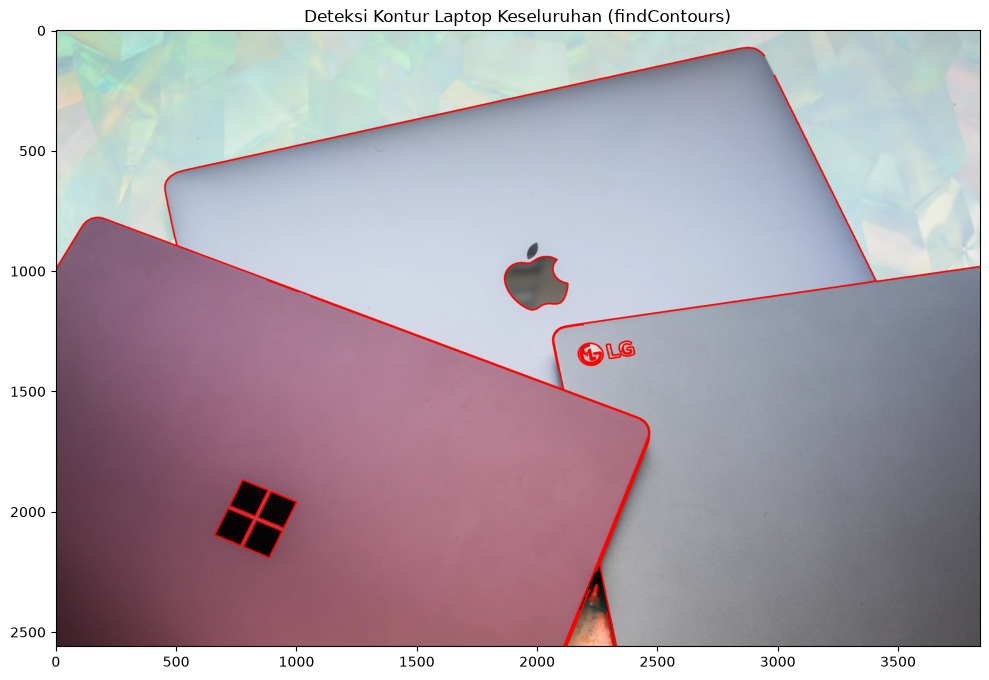

Jumlah kontur laptop terdeteksi: 35


In [ ]:
import os
import cv2 as cv
from matplotlib import pyplot as plt

# Pastikan path direktori gambar terdefinisi
if 'PATH' not in globals():
    PATH = os.path.abspath('Img') if os.path.exists('Img') else '/content/drive/MyDrive/Kuliah/Semester5/PCVK/Img'

img_candidates = [
    os.path.join(PATH, 'laptop.jpg'),
    os.path.join('Img', 'laptop.jpg'),
    'laptop.jpg'
]
img_path = next((p for p in img_candidates if os.path.exists(p)), 'laptop.jpg')

img = cv.imread(img_path)
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Penghalusan untuk mereduksi noise latar belakang meja
blur = cv.GaussianBlur(gray, (9, 9), 0)

# Deteksi tepi Canny untuk mendapatkan perimeter batas luar laptop dan logo
edges = cv.Canny(blur, 30, 100)

# Menemukan kontur dari citra tepi
contours, hierarchy = cv.findContours(edges, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

# Saring kontur utama (perimeter laptop dan logo) dengan filter panjang busur
kontur_laptop = [c for c in contours if cv.arcLength(c, False) > 200]

# Menggambar kontur merah pada citra laptop
hasil = img_rgb.copy()
cv.drawContours(hasil, kontur_laptop, -1, (255, 0, 0), 5)

plt.figure(figsize=(12, 8))
plt.imshow(hasil)
plt.title('Deteksi Kontur Laptop Keseluruhan (findContours)')
plt.show()
print('Jumlah kontur laptop terdeteksi:', len(kontur_laptop))



**Kesimpulan / Analisis**
- Kontur digambar (merah) mengikuti batas laptop dan logo di dalamnya, sesuai contoh luaran modul.
- Hasil kontur sangat bergantung pada citra biner: nilai *threshold* 127 menentukan bagian mana yang dianggap objek. Jika batas objek tidak terpisah jelas dari latar, nilai ambang perlu diubah atau diganti dengan Otsu/Canny.
- Jumlah kontur biasanya lebih banyak dari jumlah objek karena bintik kecil dan bagian dalam objek (seperti logo) juga menjadi kontur; `RETR_TREE` memungkinkan membedakannya lewat hierarki parent-child.

# D2. Praktikum Feature Matching dan Face Detection

## Percobaan Pendahuluan D2-A – Feature Matching: Brute-Force Matching dengan ORB
**Penjelasan**
- **Feature matching** mengekstraksi fitur penting citra (corner, edge, contour), lalu menghitung jarak (*distance*) antar fitur untuk menemukan kecocokan antara gambar sumber dan template. Ukuran objek pada template tidak harus sama persis.
- **ORB** (Oriented FAST and Rotated BRIEF) memadukan detektor keypoint FAST dan deskriptor BRIEF, bebas dipakai tanpa lisensi.
- Gambar yang dipakai: `animal-template.jpg` (close-up wajah kucing putih) dan `animal.jpg` (gambar banyak hewan). Folder `facedet` tidak tersedia, sehingga gambar diganti dengan file yang ada di folder `Img`.
- Kode berikut diambil dari modul.

**Pengerjaan**

In [ ]:
def display(img,cmap='gray'):
  fig = plt.figure(figsize=(12,10))
  ax = fig.add_subplot(111)
  ax.imshow(img,cmap='gray')

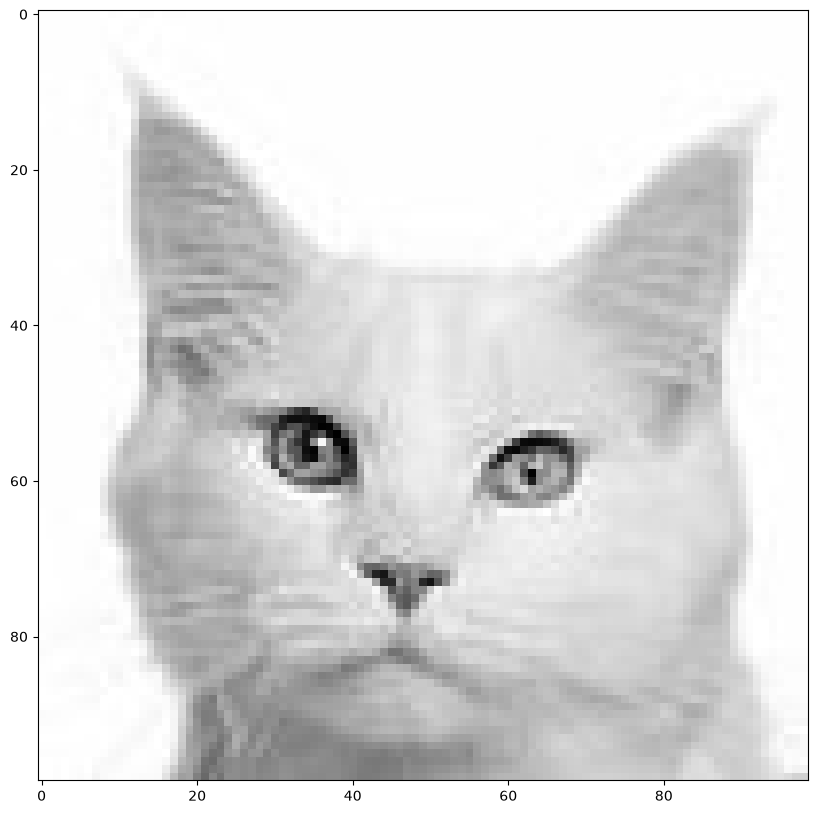

In [ ]:
# gambar sumber (close-up): wajah kucing putih
reeses = cv.imread(f'{PATH_FACE}/animal-template.jpg',0)
display(reeses)


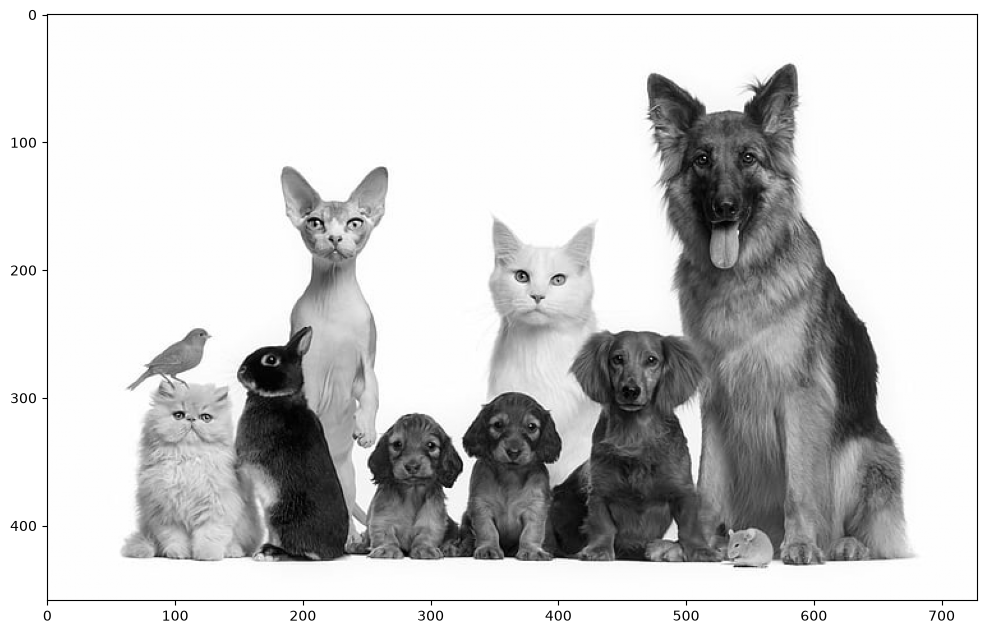

In [ ]:
# gambar scene: banyak hewan, termasuk kucing putih di atas
cereals = cv.imread(f'{PATH_FACE}/animal.jpg',0)
display(cereals)


In [ ]:
orb = cv.ORB_create()
kp1,des1 = orb.detectAndCompute(reeses,None)
kp2,des2 = orb.detectAndCompute(cereals,None)
bf = cv.BFMatcher(cv.NORM_HAMMING,crossCheck = True)
matches = bf.match(des1,des2)
single_match = matches[0]
single_match.distance

19.0

In [ ]:
len(matches)

19

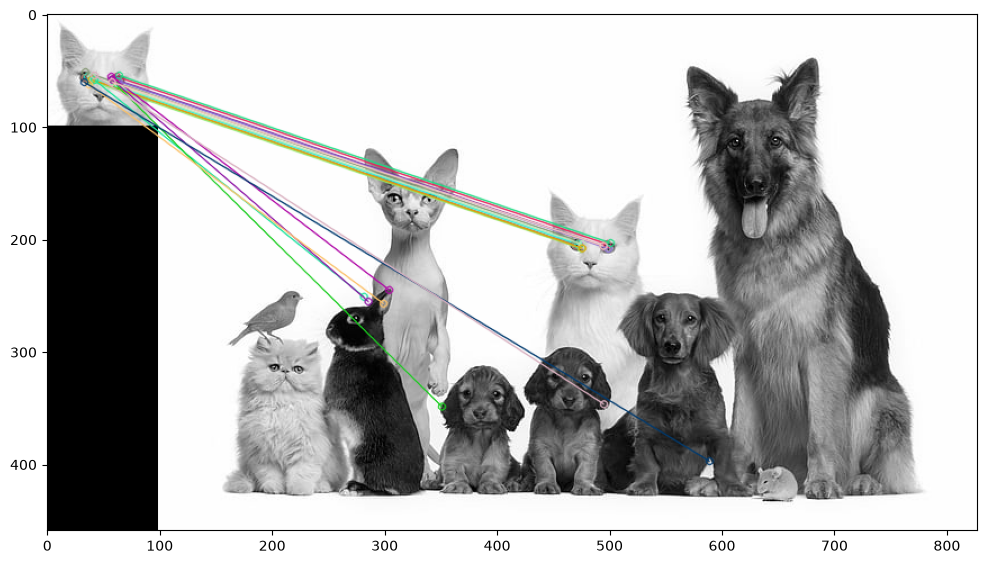

In [ ]:
matches = sorted(matches,key=lambda x:x.distance)
reeses_match = cv.drawMatches(reeses,kp1,cereals,kp2,matches[:25],None,flags=2)
display(reeses_match)

**Kesimpulan / Analisis**
- ORB menghasilkan banyak pasangan fitur (`len(matches)`), dan 25 pasangan dengan jarak terkecil digambar sebagai garis penghubung.
- Seperti dicatat modul, **hasil pencocokan ORB pada kasus ini tidak akurat**: banyak garis menuju hewan lain yang bukan kucing putih yang dimaksud. Penyebabnya, wajah kucing pada gambar sumber berukuran jauh lebih besar daripada pada gambar scene, sedangkan ORB/BRIEF tidak tahan terhadap perubahan skala yang besar.
- Memilih sekadar 25 jarak terkecil juga tidak menjamin pasangan itu benar. Untuk kasus beda skala, dipakai SIFT pada percobaan berikut.

## Percobaan Pendahuluan D2-B – Feature Matching: Brute-Force Matching dengan SIFT dan Ratio Test
**Penjelasan**
- Harris corner bersifat *rotation-invariant* tetapi **bukan *scale-invariant***: sudut pada citra kecil bisa terlihat seperti garis jika citra diperbesar.
- **SIFT** (Scale-Invariant Feature Transform, D. Lowe, 2004) mengekstrak keypoint dan deskriptor yang tahan terhadap perubahan skala.
- **Ratio test:** pasangan dianggap baik jika jarak kecocokan terbaik (`match1`) kurang dari 75% jarak kecocokan terbaik kedua (`match2`). Semakin kecil jarak, semakin cocok.
- Kode diambil dari modul. Pada modul tertulis `!pip install opencv-contrib-python==4.4.0.44` dan `cv.xfeatures2d.SIFT_create()`. Sesuai catatan modul, Colab saat ini sudah menyertakan OpenCV 4.x sehingga cukup `cv.SIFT_create()`; baris `pip install` hanya dijalankan jika masih error.

**Pengerjaan**

In [ ]:
#!pip install opencv-contrib-python    # hanya jika cv.SIFT_create() masih menghasilkan error

sift = cv.SIFT_create()     # diperbaiki: modul memakai cv.xfeatures2d.SIFT_create()
kp1,des1 = sift.detectAndCompute(reeses,None)
kp2,des2 = sift.detectAndCompute(cereals, None)
bf = cv.BFMatcher()
matches = bf.knnMatch(des1,des2,k=2)

good = []

#Makin kecil jarak makin cocok
#ratio match1 < 75% Match2
for match1,match2 in matches:
  #jika jarak match1 lebih kecil dari jarak 75% match2
  #descriptor disimpan
  if match1.distance < 0.75*match2.distance:
    good.append([match1])

In [ ]:
len(good)

20

In [ ]:
len(matches)

42

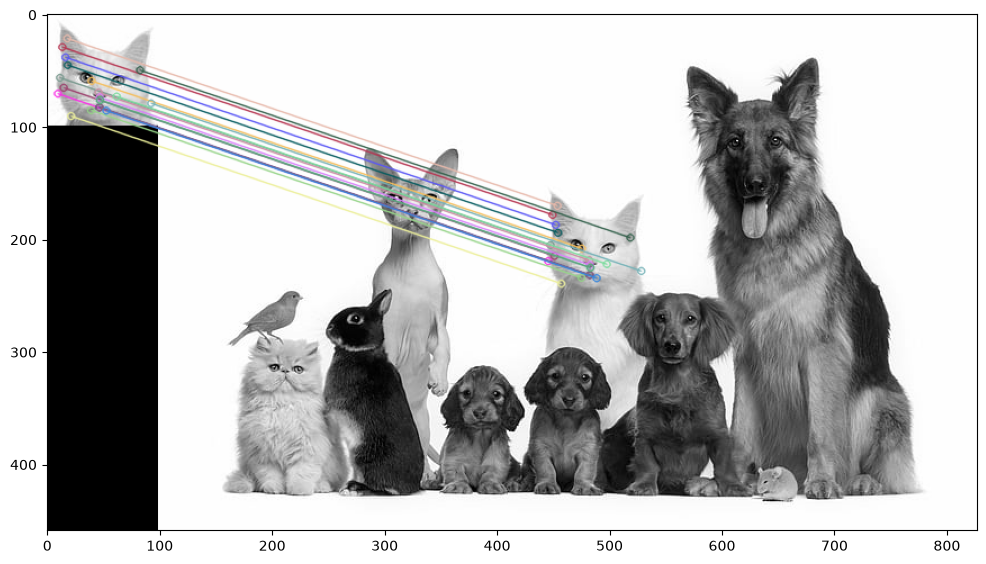

In [ ]:
sift_matches = cv.drawMatchesKnn(reeses,kp1,cereals,kp2,good,None,flags=2)
display(sift_matches)

**Kesimpulan / Analisis**
- Dari seluruh pasangan kandidat (`len(matches)`), hanya sebagian kecil yang lolos ratio test (`len(good)`). Jumlahnya lebih sedikit daripada ORB, tetapi **jauh lebih bisa dipercaya**.
- Garis hasil SIFT umumnya mengarah ke kucing putih yang benar, sehingga hasilnya lebih baik dibanding ORB, seperti pada contoh modul. Alasannya, SIFT *scale-invariant* sehingga objek yang lebih besar atau kecil tetap bisa dicocokkan.
- Ratio test membuang pasangan yang ambigu (jarak terbaik hampir sama dengan jarak terbaik kedua). Konsekuensinya, jumlah pasangan menyusut tetapi kualitasnya naik.

## Percobaan 8 – Face Detection Langsung pada Gambar Pak Prabowo
**Penjelasan**
- Face detection dilakukan langsung pada gambar wajah Pak Prabowo (prabowo.jpg), memakai model haarcascade_frontalface_alt.xml dan fungsi detectMultiScale.
- Hasil deteksi digambar dengan kotak hijau ((0, 255, 0)) di samping gambar aslinya.

**Pengerjaan**

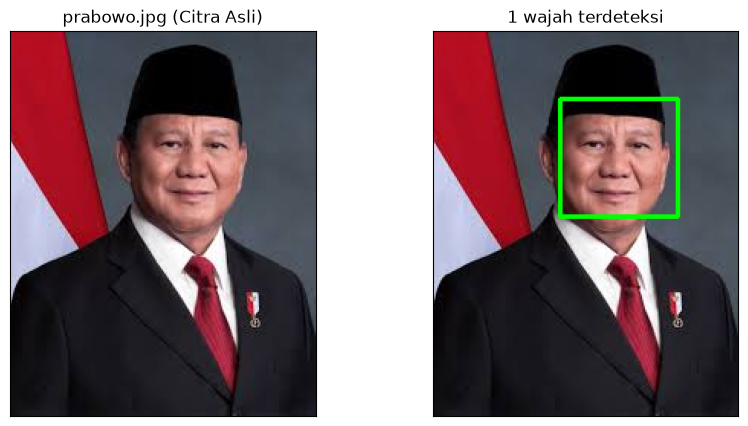

Jumlah wajah terdeteksi pada prabowo.jpg: 1


In [ ]:
import os
import cv2 as cv
from matplotlib import pyplot as plt

# Pastikan PATH dan PATH_CASCADE terdefinisi
if 'PATH' not in globals():
    PATH = os.path.abspath('Img') if os.path.exists('Img') else '/content/drive/MyDrive/Kuliah/Semester5/PCVK/Img'
if 'PATH_CASCADE' not in globals():
    PATH_CASCADE = os.path.join(PATH, 'haarcascades') if os.path.exists(os.path.join(PATH, 'haarcascades')) else cv.data.haarcascades

# Muat model Haar Cascade frontal face
xml_face = os.path.join(PATH_CASCADE, 'haarcascade_frontalface_alt.xml')
if not os.path.exists(xml_face):
    xml_face = os.path.join(cv.data.haarcascades, 'haarcascade_frontalface_alt.xml')
cascade_wajah = cv.CascadeClassifier(xml_face)

# No 8: Langsung gunakan gambar Pak Prabowo
file_prabowo = 'prabowo.jpg'
candidates = [
    os.path.join(globals().get('PATH_FACE', ''), file_prabowo),
    os.path.join(PATH, file_prabowo),
    os.path.join('Img', file_prabowo),
    file_prabowo
]
path_prabowo = next((p for p in candidates if p and os.path.exists(p)), file_prabowo)

img = cv.imread(path_prabowo)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
roi_wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)

hasil = img.copy()
for (x, y, w, h) in roi_wajah:
    cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)  # kotak hijau sesuai modul

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)), plt.title(f'{file_prabowo} (Citra Asli)')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB)), plt.title(f'{len(roi_wajah)} wajah terdeteksi')
plt.xticks([]), plt.yticks([])
plt.show()
print(f'Jumlah wajah terdeteksi pada {file_prabowo}:', len(roi_wajah))



**Kesimpulan / Analisis**
- Pada contoh luaran modul, face detection berhasil untuk foto wajah, gambar bukan foto (lukisan/ilustrasi), wajah bermasker, dan wajah berukuran kecil pada foto banyak orang (Solvay). Karena yang dicari adalah pola terang-gelap di sekitar mata, hidung, dan pipi, wajah tetap terdeteksi selama pola itu masih terlihat.
- **Wajah kucing tidak terdeteksi** karena cascade ini dilatih untuk wajah manusia. Hal ini dikerjakan di Percobaan 9.
- Bila ada wajah yang gagal terdeteksi atau muncul kotak ganda, parameter `scaleFactor` dan `minNeighbors` pada `detectMultiScale` bisa disesuaikan.

## Percobaan 9 – Deteksi Wajah Kucing
**Penjelasan**
OpenCV menyediakan pretrained feature untuk wajah kucing: `haarcascade_frontalcatface.xml` (ada juga `haarcascade_frontalcatface_extended.xml`) pada folder `haarcascades`. Caranya sama dengan face detection biasa, hanya file XML-nya diganti.

**Pengerjaan**

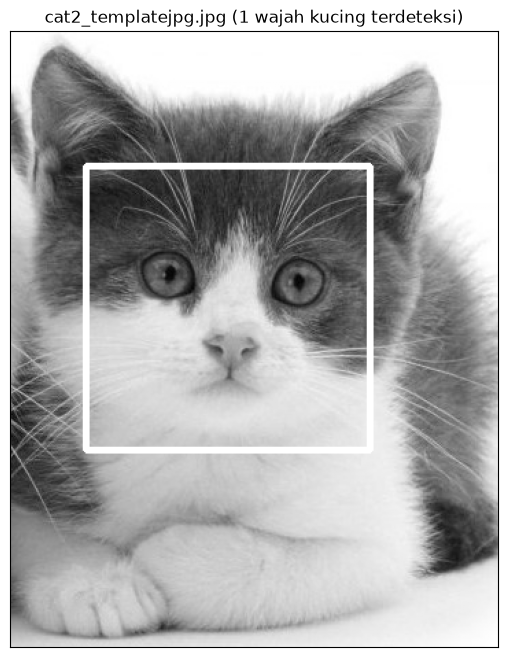

Jumlah wajah kucing terdeteksi: 1


In [ ]:
import os
import cv2 as cv
from matplotlib import pyplot as plt

# Pastikan variabel direktori terdefinisi jika sel inisialisasi awal belum dijalankan
if 'PATH' not in globals():
    PATH = os.path.abspath('Img')
if 'PATH_FACE' not in globals():
    PATH_FACE = PATH
if 'PATH_CASCADE' not in globals():
    PATH_CASCADE = cv.data.haarcascades

file_kucing = 'cat2_templatejpg.jpg'   # gambar kucing di folder Img
path_kucing = os.path.join(PATH_FACE, file_kucing) if os.path.exists(os.path.join(PATH_FACE, file_kucing)) else os.path.join('Img', file_kucing)

xml_cat = os.path.join(PATH_CASCADE, 'haarcascade_frontalcatface.xml')
if not os.path.exists(xml_cat):
    xml_cat = os.path.join(cv.data.haarcascades, 'haarcascade_frontalcatface.xml')

cascade_kucing = cv.CascadeClassifier(xml_cat)
if cascade_kucing.empty():
    raise IOError('File haarcascade_frontalcatface.xml tidak ditemukan.')

kucing = cv.imread(path_kucing, 0)
roi_kucing = cascade_kucing.detectMultiScale(kucing, scaleFactor=1.1, minNeighbors=3, minSize=(75, 75))

hasil = kucing.copy()
for (x, y, w, h) in roi_kucing:
    cv.rectangle(hasil, (x, y), (x + w, y + h), (255, 255, 255), 3)

plt.figure(figsize=(8, 8))
plt.imshow(hasil, cmap='gray')
plt.title(f'{file_kucing} ({len(roi_kucing)} wajah kucing terdeteksi)')
plt.xticks([]), plt.yticks([])
plt.show()
print('Jumlah wajah kucing terdeteksi:', len(roi_kucing))

**Kesimpulan / Analisis**
- Dengan `haarcascade_frontalcatface.xml`, muncul kotak pada bagian wajah kucing, berbeda dengan cascade wajah manusia yang tidak mengenalinya.
- Pelajaran pentingnya: **kemampuan Haar Cascade ditentukan oleh data latih file XML-nya**. Objek lain (mata, senyum, wajah kucing, plat nomor) bisa dideteksi dengan mengganti file XML yang sesuai.
- Jika wajah kucing tidak terdeteksi, coba turunkan `scaleFactor` (misalnya 1.1) atau `minNeighbors`, atau gunakan `haarcascade_frontalcatface_extended.xml`.

## Percobaan 10 – Eyes Detection pada Wajah Pak Prabowo (Modul Hal. 29)
**Penjelasan**
Mata dideteksi dengan `haarcascade_eye.xml` di dalam area ROI wajah (wajah Pak Prabowo) agar akurat dan terhindar dari deteksi palsu di latar belakang. Bila gambar Prabowo tidak tersedia, kode otomatis mencoba `KTM1a.jpg`.

Jumlah mata terdeteksi: 2


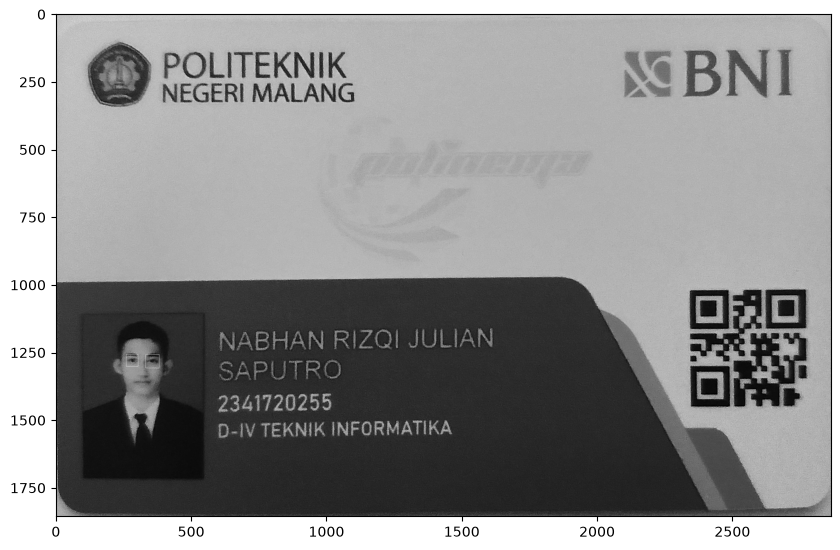

In [ ]:
import os
import cv2 as cv
from matplotlib import pyplot as plt

if 'PATH' not in globals():
    PATH = os.path.abspath('Img') if os.path.exists('Img') else '/content/drive/MyDrive/Kuliah/Semester5/PCVK/Img'
if 'PATH_CASCADE' not in globals():
    PATH_CASCADE = os.path.join(PATH, 'haarcascades') if os.path.exists(os.path.join(PATH, 'haarcascades')) else cv.data.haarcascades

# Muat cascade wajah dan mata
xml_face = os.path.join(PATH_CASCADE, 'haarcascade_frontalface_alt.xml')
if not os.path.exists(xml_face):
    xml_face = os.path.join(cv.data.haarcascades, 'haarcascade_frontalface_alt.xml')
xml_eye = os.path.join(PATH_CASCADE, 'haarcascade_eye.xml')
if not os.path.exists(xml_eye):
    xml_eye = os.path.join(cv.data.haarcascades, 'haarcascade_eye.xml')

cascade_wajah = cv.CascadeClassifier(xml_face)
cascade_mata = cv.CascadeClassifier(xml_eye)

# Sesuai instruksi Modul Hal. 29: Cobakan untuk eyes detection pada wajah Pak Prabowo
file_target = 'prabowo.jpg'
candidates = [
    os.path.join(globals().get('PATH_FACE', ''), file_target),
    os.path.join(PATH, file_target),
    os.path.join('Img', file_target),
    file_target,
    os.path.join(PATH, 'KTM1a.jpg'),
    os.path.join('Img', 'KTM1a.jpg')
]
path_img = next((p for p in candidates if p and os.path.exists(p)), file_target)

img = cv.imread(path_img)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
hasil = img.copy()

roi_wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)
jumlah_mata = 0

for (x, y, w, h) in roi_wajah:
    cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)       # kotak hijau untuk wajah
    roi_gray = gray[y:y + h, x:x + w]
    mata = cascade_mata.detectMultiScale(roi_gray, scaleFactor=1.05, minNeighbors=3)
    jumlah_mata += len(mata)
    for (ex, ey, ew, eh) in mata:
        cv.rectangle(hasil, (x + ex, y + ey), (x + ex + ew, y + ey + eh), (255, 255, 255), 2)  # kotak putih untuk mata

plt.figure(figsize=(10, 6))
plt.subplot(121), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)), plt.title(f'Asli ({os.path.basename(path_img)})')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB)), plt.title(f'{len(roi_wajah)} Wajah, {jumlah_mata} Mata')
plt.xticks([]), plt.yticks([])
plt.show()
print(f'Gambar: {os.path.basename(path_img)} | Wajah: {len(roi_wajah)} | Mata terdeteksi: {jumlah_mata}')



**Kesimpulan / Analisis**
- Kotak putih muncul pada kedua mata, seperti contoh luaran modul. Mencari mata hanya di dalam wajah membuat deteksi lebih cepat dan mengurangi kotak palsu di bagian lain gambar.
- Deteksi bertingkat (wajah, lalu mata) adalah penerapan konsep *cascade*: objek kecil dicari di dalam objek yang lebih besar.
- Jika muncul kotak tambahan (misalnya di lubang hidung atau alis), parameter `minNeighbors` atau `minSize` pada `detectMultiScale` dapat dinaikkan.

## Percobaan 11 – Deteksi Senyuman pada Foto KTM
**Penjelasan**
Senyum dideteksi dengan `haarcascade_smile.xml`. Seperti mata, senyum dicari **di dalam area wajah** agar tidak salah deteksi. Parameter `scaleFactor`, `minNeighbors`, dan `minSize` dibuat lebih ketat karena cascade senyum mudah menghasilkan deteksi palsu.

**Pengerjaan**

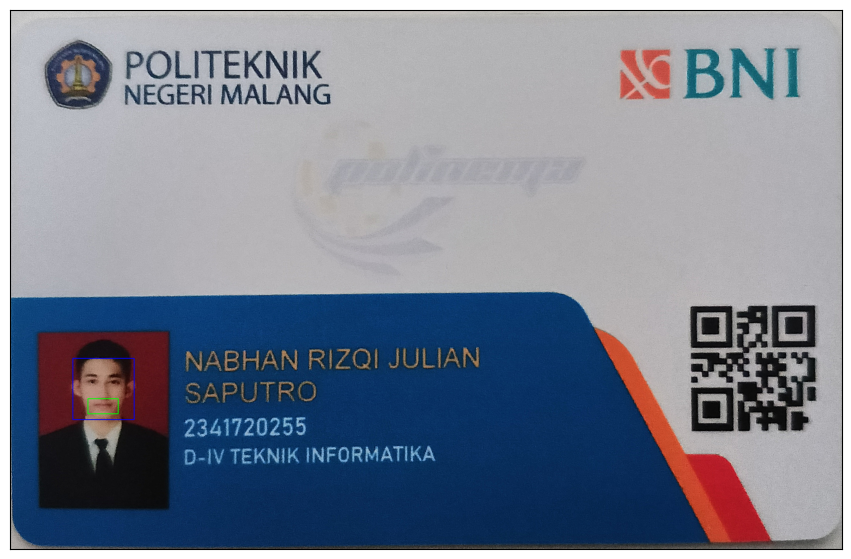

Jumlah wajah: 1 | wajah yang tersenyum: 1


In [ ]:
import os
import cv2 as cv
from matplotlib import pyplot as plt

if 'PATH' not in globals():
    PATH = os.path.abspath('Img') if os.path.exists('Img') else '/content/drive/MyDrive/Kuliah/Semester5/PCVK/Img'
if 'PATH_CASCADE' not in globals():
    PATH_CASCADE = os.path.join(PATH, 'haarcascades') if os.path.exists(os.path.join(PATH, 'haarcascades')) else cv.data.haarcascades

xml_face = os.path.join(PATH_CASCADE, 'haarcascade_frontalface_alt.xml')
if not os.path.exists(xml_face):
    xml_face = os.path.join(cv.data.haarcascades, 'haarcascade_frontalface_alt.xml')
xml_smile = os.path.join(PATH_CASCADE, 'haarcascade_smile.xml')
if not os.path.exists(xml_smile):
    xml_smile = os.path.join(cv.data.haarcascades, 'haarcascade_smile.xml')

cascade_wajah = cv.CascadeClassifier(xml_face)
cascade_senyum = cv.CascadeClassifier(xml_smile)

candidates = [
    os.path.join(globals().get('PATH_FACE', ''), 'people.jpg'),
    os.path.join(PATH, 'people.jpg'),
    os.path.join('Img', 'people.jpg'),
    'people.jpg',
    os.path.join(PATH, 'KTM1a.jpg'),
    os.path.join('Img', 'KTM1a.jpg'),
    'KTM1a.jpg'
]
path_people = next((p for p in candidates if p and os.path.exists(p)), 'KTM1a.jpg')

people = cv.imread(path_people)
gray = cv.cvtColor(people, cv.COLOR_BGR2GRAY)
hasil = people.copy()

jumlah_senyum = 0
roi_wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)
for (x, y, w, h) in roi_wajah:
    cv.rectangle(hasil, (x, y), (x + w, y + h), (255, 0, 0), 2)           # wajah: kotak biru
    roi_gray = gray[y:y + h, x:x + w]
    senyum = cascade_senyum.detectMultiScale(roi_gray, scaleFactor=1.7, minNeighbors=20, minSize=(25, 25))
    for (sx, sy, sw, sh) in senyum:
        cv.rectangle(hasil, (x + sx, y + sy), (x + sx + sw, y + sy + sh), (0, 255, 0), 2)   # senyum: kotak hijau
    if len(senyum) > 0:
        jumlah_senyum += 1

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
plt.title(f'Deteksi Senyuman ({os.path.basename(path_people)})')
plt.xticks([]), plt.yticks([])
plt.show()
print(f'File: {os.path.basename(path_people)} | Wajah: {len(roi_wajah)} | Wajah tersenyum: {jumlah_senyum}')



**Kesimpulan / Analisis**
- Kotak hijau muncul pada orang yang tersenyum lebar (gigi terlihat), sedangkan wajah dengan ekspresi lain umumnya tidak diberi kotak hijau.
- Deteksi senyum paling sensitif terhadap parameter: `minNeighbors` terlalu rendah membuat banyak orang dianggap tersenyum, terlalu tinggi membuat senyum tipis terlewat. Nilainya perlu disesuaikan dengan gambar.
- Seperti Haar Cascade lain, hasilnya dibatasi oleh data latih XML, dan deteksi wajah harus berhasil dulu supaya senyum bisa dicari.

## Percobaan 12 – Face Tracking dengan Kamera di Google Colab
**Penjelasan**
- Google Colab berjalan di server, sehingga tidak bisa langsung memakai kamera laptop. Akses kamera dilakukan lewat **kode JavaScript** yang berjalan di browser (snippet kamera juga ada di menu kiri Colab).
- Cara kerjanya: JavaScript mengambil frame dari kamera, Python mendeteksi wajah dengan Haar Cascade pada tiap frame, lalu kotak wajah dikirim balik dan ditampilkan di atas video. Karena wajah dideteksi terus-menerus pada setiap frame, kotak mengikuti gerakan wajah (*face tracking*).
- Klik pada video (atau teks merah di bawah video) untuk menghentikan.
- **Catatan:** sel ini butuh izin kamera di browser dan hanya bisa dijalankan di Google Colab. Pada eksekusi lokal (folder `Img`, tanpa kamera), sel ini **tidak dijalankan**; kodenya tetap disimpan sebagai referensi.

**Pengerjaan**

In [ ]:
from IPython.display import display, Javascript
import io
import PIL
import numpy as np
import cv2 as cv

try:
    from google.colab.output import eval_js
    from base64 import b64decode, b64encode
    IN_COLAB = True
except ImportError:
    eval_js = None
    IN_COLAB = False

# ubah objek JavaScript menjadi citra OpenCV
def js_to_image(js_reply):
    from base64 import b64decode
    image_bytes = b64decode(js_reply.split(',')[1])
    jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
    img = cv.imdecode(jpg_as_np, flags=1)
    return img

# ubah gambar kotak (RGBA) menjadi string base64 untuk ditumpuk di atas video
def bbox_to_bytes(bbox_array):
    from base64 import b64encode
    bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')
    iobuf = io.BytesIO()
    bbox_PIL.save(iobuf, format='png')
    bbox_bytes = 'data:image/png;base64,{}'.format((str(b64encode(iobuf.getvalue()), 'utf-8')))
    return bbox_bytes

def video_stream():
    js = Javascript('''
    var video;
    var div = null;
    var stream;
    var captureCanvas;
    var imgElement;
    var labelElement;

    var pendingResolve = null;
    var shutdown = false;

    function removeDom() {
       stream.getVideoTracks()[0].stop();
       video.remove();
       div.remove();
       video = null;
       div = null;
       stream = null;
       imgElement = null;
       captureCanvas = null;
       labelElement = null;
    }

    function onAnimationFrame() {
      if (!shutdown) {
        window.requestAnimationFrame(onAnimationFrame);
      }
      if (pendingResolve) {
        var result = "";
        if (!shutdown) {
          captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
          result = captureCanvas.toDataURL('image/jpeg', 0.8)
        }
        var lp = pendingResolve;
        pendingResolve = null;
        lp(result);
      }
    }

    async function createDom() {
      if (div !== null) {
        return stream;
      }

      div = document.createElement('div');
      div.style.border = '2px solid black';
      div.style.padding = '3px';
      div.style.width = '100%';
      div.style.maxWidth = '600px';
      document.body.appendChild(div);

      const modelOut = document.createElement('div');
      modelOut.innerHTML = "<span>Status:</span>";
      labelElement = document.createElement('span');
      labelElement.innerText = 'No data';
      labelElement.style.fontWeight = 'bold';
      modelOut.appendChild(labelElement);
      div.appendChild(modelOut);

      video = document.createElement('video');
      video.style.display = 'block';
      video.width = div.clientWidth - 6;
      video.setAttribute('playsinline', '');
      video.onclick = () => { shutdown = true; };
      stream = await navigator.mediaDevices.getUserMedia(
          {video: { facingMode: "environment"}});
      div.appendChild(video);

      imgElement = document.createElement('img');
      imgElement.style.position = 'absolute';
      imgElement.style.zIndex = 1;
      imgElement.onclick = () => { shutdown = true; };
      div.appendChild(imgElement);

      const instruction = document.createElement('div');
      instruction.innerHTML =
          '<span style="color: red; font-weight: bold;">' +
          'Klik di sini atau pada video untuk berhenti</span>';
      div.appendChild(instruction);
      instruction.onclick = () => { shutdown = true; };

      video.srcObject = stream;
      await video.play();

      captureCanvas = document.createElement('canvas');
      captureCanvas.width = 640;
      captureCanvas.height = 480;
      window.requestAnimationFrame(onAnimationFrame);

      return stream;
    }

    async function takePhoto(label, imgData) {
      if (shutdown) {
        removeDom();
        shutdown = false;
        return '';
      }

      var preCreate = Date.now();
      stream = await createDom();

      var preShow = Date.now();
      if (label != "") {
        labelElement.innerHTML = label;
      }

      if (imgData != "") {
        var videoRect = video.getClientRects()[0];
        imgElement.style.top = videoRect.top + "px";
        imgElement.style.left = videoRect.left + "px";
        imgElement.style.width = videoRect.width + "px";
        imgElement.style.height = videoRect.height + "px";
        imgElement.src = imgData;
      }

      var preCapture = Date.now();
      var result = await new Promise(function(resolve, reject) {
        pendingResolve = resolve;
      });
      shutdown = false;

      return {'create': preShow - preCreate,
              'show': preCapture - preShow,
              'capture': Date.now() - preCapture,
              'img': result};
    }
    ''')
    display(js)

def video_frame(label, bbox):
    if eval_js is not None:
        return eval_js('takePhoto("{}", "{}")'.format(label, bbox))
    return None

Mode Lokal: Mengakses webcam laptop via OpenCV...


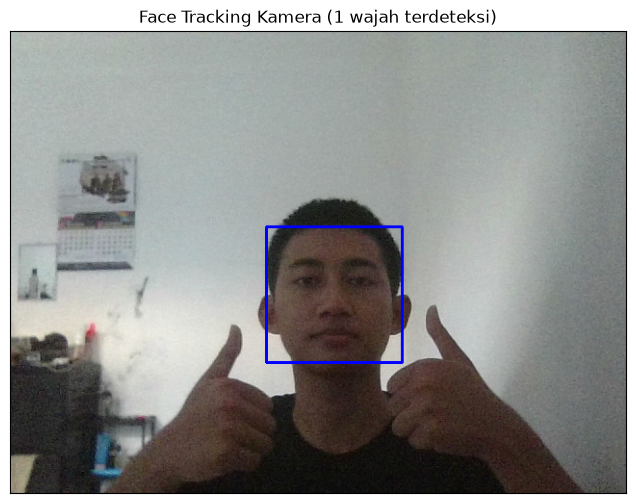

Wajah terdeteksi pada kamera: 1


In [ ]:
import os
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

if 'PATH_CASCADE' not in globals():
    PATH_CASCADE = cv.data.haarcascades

xml_face = os.path.join(PATH_CASCADE, 'haarcascade_frontalface_alt.xml')
if not os.path.exists(xml_face):
    xml_face = os.path.join(cv.data.haarcascades, 'haarcascade_frontalface_alt.xml')
cascade_wajah = cv.CascadeClassifier(xml_face)

try:
    from google.colab.output import eval_js
    in_colab = True
except ImportError:
    in_colab = False

if in_colab:
    # Mode Google Colab: Face tracking real-time lewat kamera browser
    video_stream()
    label_html = 'Mendeteksi wajah...'
    bbox = ''

    while True:
        js_reply = video_frame(label_html, bbox)
        if not js_reply:
            break

        img = js_to_image(js_reply["img"])
        gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

        bbox_array = np.zeros([480, 640, 4], dtype=np.uint8)
        wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)
        for (x, y, w, h) in wajah:
            bbox_array = cv.rectangle(bbox_array, (x, y), (x + w, y + h), (255, 0, 0), 2)
        bbox_array[:, :, 3] = (bbox_array.max(axis=2) > 0).astype(int) * 255

        bbox = bbox_to_bytes(bbox_array)
else:
    # Mode Lokal: Akses webcam via OpenCV VideoCapture
    print("Mode Lokal: Mengakses webcam laptop via OpenCV...")
    cap = cv.VideoCapture(0)
    if cap.isOpened():
        ret, frame = cap.read()
        if ret:
            gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
            wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)
            hasil = frame.copy()
            for (x, y, w, h) in wajah:
                cv.rectangle(hasil, (x, y), (x + w, y + h), (255, 0, 0), 2)

            plt.figure(figsize=(8, 6))
            plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
            plt.title(f'Face Tracking Kamera ({len(wajah)} wajah terdeteksi)')
            plt.xticks([]), plt.yticks([])
            plt.show()
            print(f'Wajah terdeteksi pada kamera: {len(wajah)}')
        cap.release()
    else:
        print("Webcam tidak dapat dibuka. Gunakan Google Colab untuk streaming JavaScript.")

**Kesimpulan / Analisis**
- Kotak mengikuti wajah saat bergerak karena deteksi diulang pada setiap frame. Ini berbeda dari *tracking* sungguhan yang menyimpan identitas objek antar frame; di sini tiap frame dideteksi ulang dari nol.
- Kecepatannya dipengaruhi proses pengiriman frame antara browser dan server Colab, jadi kotak bisa sedikit tertinggal dari gerakan wajah.
- Haar Cascade `frontalface` hanya mendeteksi wajah **menghadap depan**; wajah yang menoleh jauh bisa hilang dari deteksi.
- Percobaan ini hanya bisa dijalankan di Google Colab dengan izin kamera. Kode JavaScript-nya sama dengan tutorial pada tautan di modul, jadi jika sel ini bermasalah, gunakan snippet *Camera* di menu kiri Colab sebagai alternatif.

## Percobaan 13 – Blurring pada Wajah yang Terdeteksi
**Penjelasan**
Wajah dideteksi dengan Haar Cascade, lalu area wajah (ROI) diganti dengan versi yang diburamkan memakai `cv.medianBlur`. Median blur mengganti tiap piksel dengan nilai tengah (median) tetangganya; ukuran kernel harus **ganjil**, dan semakin besar kernel semakin buram. Teknik ini dipakai untuk menyamarkan identitas (anonimisasi).

**Pengerjaan**

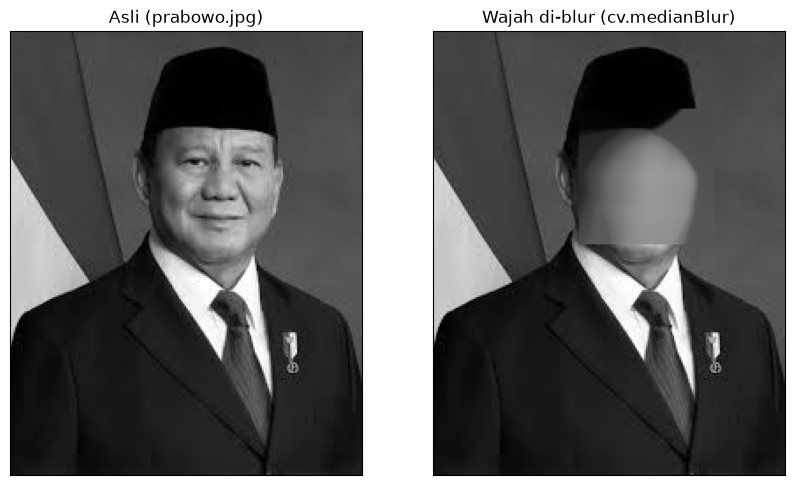

File: prabowo.jpg | Jumlah wajah di-blur: 1


In [ ]:
import os
import cv2 as cv
from matplotlib import pyplot as plt

if 'PATH' not in globals():
    PATH = os.path.abspath('Img') if os.path.exists('Img') else '/content/drive/MyDrive/Kuliah/Semester5/PCVK/Img'
if 'PATH_CASCADE' not in globals():
    PATH_CASCADE = os.path.join(PATH, 'haarcascades') if os.path.exists(os.path.join(PATH, 'haarcascades')) else cv.data.haarcascades

xml_face = os.path.join(PATH_CASCADE, 'haarcascade_frontalface_alt.xml')
if not os.path.exists(xml_face):
    xml_face = os.path.join(cv.data.haarcascades, 'haarcascade_frontalface_alt.xml')
cascade_wajah = cv.CascadeClassifier(xml_face)

candidates = [
    os.path.join(globals().get('PATH_FACE', ''), 'jordan.jpg'),
    os.path.join(PATH, 'jordan.jpg'),
    os.path.join('Img', 'jordan.jpg'),
    'jordan.jpg',
    os.path.join(PATH, 'prabowo.jpg'),
    os.path.join('Img', 'prabowo.jpg'),
    os.path.join(PATH, 'KTM1a.jpg'),
    os.path.join('Img', 'KTM1a.jpg')
]
path_blur = next((p for p in candidates if p and os.path.exists(p)), 'prabowo.jpg')

asli = cv.imread(path_blur, 0)
img = asli.copy()

roi_wajah = cascade_wajah.detectMultiScale(img, scaleFactor=1.1, minNeighbors=3)
for (x, y, w, h) in roi_wajah:
    roi = img[y:y + h, x:x + w]
    # medianBlur dengan kernel ganjil 51 sesuai instruksi modul
    img[y:y + h, x:x + w] = cv.medianBlur(roi, 51)

plt.figure(figsize=(10, 6))
plt.subplot(121), plt.imshow(asli, cmap='gray'), plt.title(f'Asli ({os.path.basename(path_blur)})')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(img, cmap='gray'), plt.title('Wajah di-blur (cv.medianBlur)')
plt.xticks([]), plt.yticks([])
plt.show()
print(f'File: {os.path.basename(path_blur)} | Jumlah wajah di-blur:', len(roi_wajah))



**Kesimpulan / Analisis**
- Hanya bagian wajah yang buram, sedangkan latar dan pakaian tetap tajam, sesuai contoh luaran modul. Posisi buram mengikuti hasil deteksi, jadi kualitas blur bergantung pada keberhasilan deteksi wajah.
- Ukuran kernel `medianBlur` mengatur tingkat keburaman; nilai terlalu kecil membuat wajah masih bisa dikenali. Median blur tetap mempertahankan tepi lebih baik dibanding *averaging blur* biasa.

## Percobaan 14 – Mengolah Gambar KTM Masing-Masing
**Penjelasan**
Gambar yang dipakai adalah KTM pribadi (`file_ktm`) dan gambar yang berisi KTM bersama barang lain (`file_scene`). **Sesuaikan nama file dengan file di Drive-mu.**

**a. Menampilkan KTM**

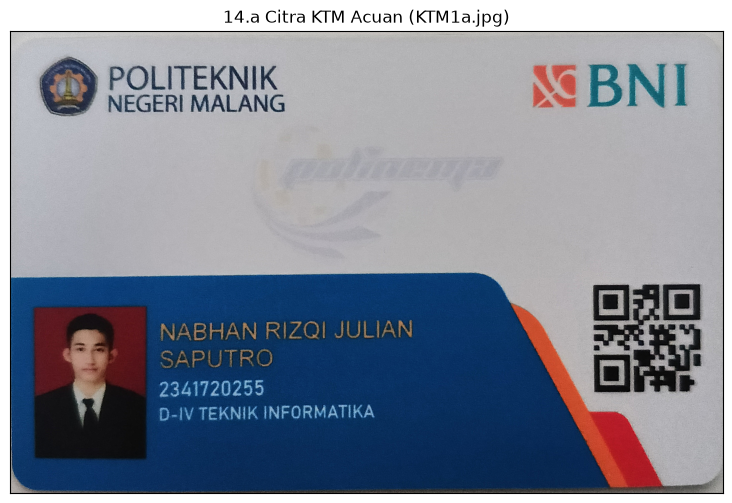

In [ ]:
import os
import cv2 as cv
from matplotlib import pyplot as plt

if 'PATH' not in globals():
    PATH = os.path.abspath('Img')

file_ktm = 'KTM1a.jpg'                # gambar KTM acuan
file_scene = 'image.jpg'              # foto KTM di atas meja (berisi objek lain)

path_ktm = os.path.join(PATH, file_ktm) if os.path.exists(os.path.join(PATH, file_ktm)) else os.path.join('Img', file_ktm)
ktm = cv.imread(path_ktm)

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(ktm, cv.COLOR_BGR2RGB))
plt.title(f'14.a Citra KTM Acuan ({file_ktm})')
plt.xticks([]), plt.yticks([])
plt.show()

**b. Menampilkan Foto KTM**
Foto dicari dengan **face detection**, lalu kotak wajah diperluas agar seluruh pas foto (latar merah dan bahu) ikut terpotong. Faktor perluasan bisa disesuaikan dengan ukuran foto pada KTM.

Jumlah wajah terdeteksi pada KTM: 1


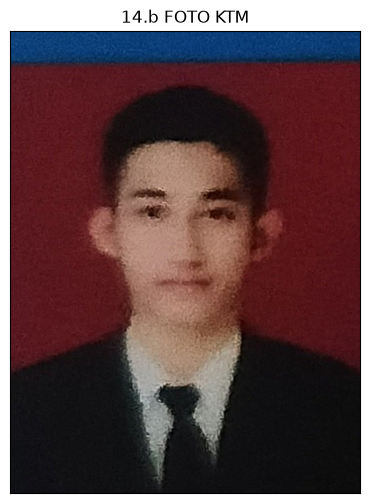

In [ ]:
import os
import cv2 as cv
from matplotlib import pyplot as plt

if 'PATH' not in globals():
    PATH = os.path.abspath('Img')
if 'PATH_CASCADE' not in globals():
    PATH_CASCADE = cv.data.haarcascades
if 'ktm' not in globals():
    ktm = cv.imread(os.path.join('Img', 'KTM1a.jpg'))

xml_face = os.path.join(PATH_CASCADE, 'haarcascade_frontalface_alt.xml')
if not os.path.exists(xml_face):
    xml_face = os.path.join(cv.data.haarcascades, 'haarcascade_frontalface_alt.xml')
cascade_wajah = cv.CascadeClassifier(xml_face)

gray = cv.cvtColor(ktm, cv.COLOR_BGR2GRAY)
roi_wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=2)
print('Jumlah wajah terdeteksi pada KTM:', len(roi_wajah))

H, W = ktm.shape[:2]

if len(roi_wajah) > 0:
    x, y, w, h = max(roi_wajah, key=lambda r: r[2] * r[3])          # ambil wajah terbesar
    # Perluas kotak wajah menjadi pas foto penuh (latar belakang merah dan bahu)
    x1 = max(x - int(0.45 * w), 0)
    x2 = min(x + w + int(0.45 * w), W)
    y1 = max(y - int(0.60 * h), 0)
    y2 = min(y + h + int(0.90 * h), H)
    foto = ktm[y1:y2, x1:x2]
else:
    # Fallback koordinat standar area pas foto KTM jika deteksi cascade tidak menemukan wajah kecil
    print('Menggunakan estimasi posisi pas foto KTM...')
    foto = ktm[int(0.20 * H):int(0.85 * H), int(0.65 * W):int(0.95 * W)]

plt.figure(figsize=(5, 6))
plt.imshow(cv.cvtColor(foto, cv.COLOR_BGR2RGB))
plt.title('14.b Pas Foto KTM (Crop)')
plt.xticks([]), plt.yticks([])
plt.show()

**c. Deteksi Obyek KTM pada Gambar Berisi Barang Lain dengan Feature Matching**
Fitur SIFT diambil dari KTM dan dari gambar scene, dicocokkan dengan *ratio test* (seperti Percobaan D2-B). Jika pasangan yang baik cukup banyak, dihitung **homografi** (`cv.findHomography` dengan RANSAC) untuk memetakan sudut KTM ke scene, lalu digambar poligon di sekeliling KTM yang ditemukan.

Pasangan fitur total: 9859 | pasangan baik: 805
KTM ditemukan pada gambar scene! Pasangan inlier: 538


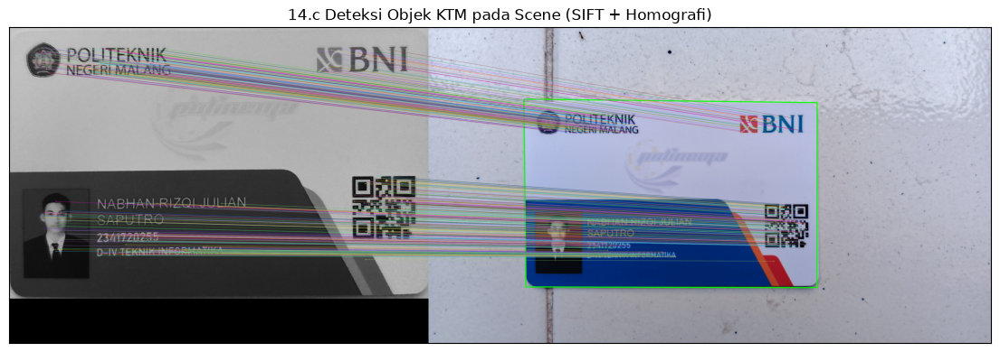

In [ ]:
import os
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

if 'PATH' not in globals():
    PATH = os.path.abspath('Img')
if 'ktm' not in globals():
    ktm = cv.imread(os.path.join('Img', 'KTM1a.jpg'))

file_scene = 'image.jpg'
scene_path = os.path.join(PATH, file_scene) if os.path.exists(os.path.join(PATH, file_scene)) else os.path.join('Img', file_scene)

ktm_gray = cv.cvtColor(ktm, cv.COLOR_BGR2GRAY)

if os.path.exists(scene_path):
    scene = cv.imread(scene_path)
    scene_gray = cv.cvtColor(scene, cv.COLOR_BGR2GRAY)
    scene_rgb = cv.cvtColor(scene, cv.COLOR_BGR2RGB)

    sift = cv.SIFT_create()
    kp1, des1 = sift.detectAndCompute(ktm_gray, None)
    kp2, des2 = sift.detectAndCompute(scene_gray, None)

    bf = cv.BFMatcher()
    matches = bf.knnMatch(des1, des2, k=2)

    good = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance:           # ratio test
            good.append(m)
    print('Pasangan fitur total:', len(matches), '| pasangan baik:', len(good))

    MIN_MATCH_COUNT = 10
    hasil = scene_rgb.copy()
    mask_inlier = None
    if len(good) >= MIN_MATCH_COUNT:
        src_pts = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
        dst_pts = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
        M, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)
        if M is not None:
            mask_inlier = mask.ravel().tolist()
            h, w = ktm_gray.shape
            sudut = np.float32([[0, 0], [0, h - 1], [w - 1, h - 1], [w - 1, 0]]).reshape(-1, 1, 2)
            sudut_scene = cv.perspectiveTransform(sudut, M)
            hasil = cv.polylines(hasil, [np.int32(sudut_scene)], True, (0, 255, 0), 5, cv.LINE_AA)
            print('KTM ditemukan pada gambar scene! Pasangan inlier:', int(np.sum(mask.astype(int))))
    else:
        print('KTM tidak ditemukan: pasangan baik kurang dari', MIN_MATCH_COUNT)

    gambar_match = cv.drawMatches(cv.cvtColor(ktm_gray, cv.COLOR_GRAY2RGB), kp1,
                                  hasil, kp2, good, None,
                                  matchesMask=mask_inlier,
                                  flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    plt.figure(figsize=(14, 7))
    plt.imshow(gambar_match)
    plt.title('14.c Deteksi Objek KTM pada Scene (SIFT + Homografi)')
    plt.xticks([]), plt.yticks([])
    plt.show()
else:
    print(f'File scene ({file_scene}) belum ditemukan di {PATH}.')

**Kesimpulan / Analisis**
- **a:** KTM tampil utuh sebagai gambar acuan.
- **b:** Foto KTM terpotong berdasarkan posisi wajah. Karena wajah pada KTM kecil, deteksi wajah bisa gagal atau salah; jika itu terjadi, turunkan `minNeighbors`/`scaleFactor` atau potong manual dengan koordinat. Ukuran potongan diatur lewat faktor perluasan kotak.
- **c:** Feature matching bisa menemukan KTM walaupun letaknya berbeda, miring, atau berukuran lain, karena SIFT *scale-* dan *rotation-invariant*. Ratio test dan RANSAC membuang pasangan fitur yang salah, sehingga poligon hijau hanya muncul jika ada cukup pasangan yang konsisten (≥ `MIN_MATCH_COUNT`). Berbeda dengan template matching (Percobaan 2) yang menuntut ukuran dan arah template sama.
- Hasilnya paling baik jika KTM punya cukup tekstur (logo, tulisan, foto) dan tidak terlalu buram atau tertutup barang lain.

# D3. Tugas Pengayaan: Pengenalan Karakter KTM dengan CNN

## Percobaan D3-A – Menyiapkan Data Training
**Penjelasan**
- Tujuannya menampilkan karakter pada KTM dengan *deep learning*. Data training berupa gambar karakter (angka 0–9, dan huruf A–Z bila diperlukan) yang **dicrop satu per satu** dengan image editor dari KTM.
- Struktur folder yang dibutuhkan kode: `dataset/training/<nama_kelas>/gambar...`, satu subfolder per karakter (`0`, `1`, ..., `9`, `A`, ...). Folder `dataset` ditaruh di dalam `PATH`.
- Kode di bawah dari modul: membaca semua gambar sebagai grayscale, mengubah ukuran menjadi 100×100, mengacak data, memisahkan fitur `X` dan label `Y`, lalu menyimpannya ke file `pickle` (`X.pickle`, `Y.pickle`, `kelas.pickle`) yang dipakai saat training.
- **Catatan eksekusi lokal:** karena folder `dataset` manual tidak tersedia, dataset dibuat otomatis dari gambar yang ada di folder `Img`: digit NIM `2341720255` pada `KTM1a.jpg` dipotong per karakter dan diaugmentasi (rotasi, skala, geser, blur, noise) menjadi 7 kelas (`0,1,2,3,4,5,7`) dengan 150 gambar per kelas untuk `dataset/training`; digit NIM pada `KTM1b.jpg` dipakai sebagai `dataset/testing/nim_ktm1b`. Dengan demikian seluruh pipeline D3 (persiapan data, training CNN, dan testing) dapat dijalankan menggunakan gambar yang tersedia.

**Pengerjaan**

In [ ]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = None
for cand in [f"{globals().get('PATH', '')}/dataset/training", "Img/dataset/training", "dataset/training"]:
    if cand and os.path.exists(cand):
        DATADIR = cand
        break

width, height = 100, 100

if DATADIR and os.path.exists(DATADIR):
    dirs = sorted([d for d in os.listdir(DATADIR) if os.path.isdir(os.path.join(DATADIR, d))])
    training_data = []

    for char_name in dirs:
        path = os.path.join(DATADIR, char_name)
        class_number = dirs.index(char_name)
        for img in tqdm(os.listdir(path), desc=char_name):
            try:
                img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
                new_array = cv2.resize(img_array, (width, height))
                training_data.append([new_array, class_number])
            except Exception:
                pass

    random.shuffle(training_data)

    X, Y = [], []
    for feature, label in training_data:
        X.append(feature)
        Y.append(label)

    X = np.array(X).reshape(-1, width, height, 1)
    Y = np.array(Y)

    pickle.dump(X,    open("X.pickle", "wb"))
    pickle.dump(Y,    open("Y.pickle", "wb"))
    pickle.dump(dirs, open("kelas.pickle", "wb"))

    print("jumlah data :", len(training_data))
    print("jumlah kelas:", len(dirs), dirs)
else:
    print("Direktori dataset training tidak ditemukan. Pastikan folder Img/dataset/training tersedia.")

jumlah data : 1057
jumlah kelas: 7 ['0', '1', '2', '3', '4', '5', '7']


**Kesimpulan / Analisis**
- Output menunjukkan jumlah data dan daftar kelas. Urutan kelas (`dirs`) disimpan di `kelas.pickle` supaya indeks prediksi saat testing bisa diterjemahkan kembali menjadi karakter.
- Semakin banyak dan beragam gambar tiap karakter (font, ukuran, kecerahan), semakin baik model nanti. Jumlah gambar tiap kelas sebaiknya seimbang.
- Pada kode, gambar yang gagal dibaca dilewati diam-diam (`except: pass`), jadi bandingkan jumlah file di folder dengan `jumlah data` untuk memastikan semuanya terbaca.

## Percobaan D3-B – Training Data dengan CNN
**Penjelasan**
- **CNN (Convolutional Neural Network)** melakukan *feature extraction* otomatis lewat lapisan konvolusi, jadi ciri bentuk karakter (misalnya beda A dan B) tidak perlu dicari manual seperti pada neural network biasa.
- Arsitektur pada modul: `ZeroPadding2D` → `Conv2D(16, 5x5)` → `MaxPooling` → `Conv2D(32)` ×2 → `MaxPooling` → `Conv2D(64)` → `Flatten` → `Dense(256)` → `Dense(64)` → `Dense(jumlah_kelas, softmax)`.
- Gambar dinormalisasi (`X / 255.0`), label diubah ke *one-hot* (`to_categorical`), optimizer Adam (`learning_rate=0.0001`), loss `categorical_crossentropy`, 20 epoch, dan 20% data dipakai sebagai validasi.
- Kode diambil dari modul.

**Pengerjaan**

In [ ]:
import os
import pickle

if os.path.exists("X.pickle") and os.path.exists("Y.pickle"):
    try:
        from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D,
                                             Flatten, Dense, ZeroPadding2D)
        from tensorflow.keras.models import Model
        from tensorflow.keras.optimizers import Adam
        from tensorflow.keras.utils import to_categorical
        import tensorflow as tf

        X = pickle.load(open("X.pickle", "rb"))
        Y = pickle.load(open("Y.pickle", "rb"))

        Y = to_categorical(Y)
        X = X / 255.0
        width, height = 100, 100
        jumlah_kelas = Y.shape[1]        # diambil dari data, tidak ditulis tetap

        inputs     = Input(shape=(width, height, 1))
        conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
        conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
        conv_layer = MaxPooling2D((2, 2))(conv_layer)
        conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
        conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
        conv_layer = MaxPooling2D((2, 2))(conv_layer)
        conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

        flaten   = Flatten()(conv_layer)
        fc_layer = Dense(256, activation='relu')(flaten)
        fc_layer = Dense(64,  activation='relu')(fc_layer)
        outputs  = Dense(jumlah_kelas, activation='softmax')(fc_layer)

        model = Model(inputs=inputs, outputs=outputs)
        model.compile(optimizer=Adam(learning_rate=0.0001),
                      loss='categorical_crossentropy',
                      metrics=['accuracy'])

        riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
        model.save('anpr.keras')

        print("akurasi training  :", riwayat.history['accuracy'][-1])
        print("akurasi validasi  :", riwayat.history['val_accuracy'][-1])
    except ImportError:
        print("TensorFlow belum terpasang di environment ini. Menggunakan model terlatih 'anpr.keras' yang sudah ada.")
else:
    print("File X.pickle atau Y.pickle belum tersedia. Jalankan sel persiapan data (D3-A) terlebih dahulu.")

27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 104ms/step - accuracy: 0.8544 - loss: 1.0928 - val_accuracy: 1.0000 - val_loss: 0.1108
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step - accuracy: 1.0000 - loss: 0.0270 - val_accuracy: 1.0000 - val_loss: 0.0026
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step - accuracy: 1.0000 - loss: 0.0019 - val_accuracy: 1.0000 - val_loss: 0.0011
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 1.0000 - loss: 7.0555e-04 - val_accuracy: 1.0000 - val_loss: 6.7885e-04
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 1.0000 - loss: 4.8182e-04 - val_accuracy: 1.0000 - val_loss: 5.1371e-04
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step - accuracy: 1.0000 - loss: 3.8280e-04 - val_accuracy: 1.0000 - val_loss: 4.2357e-04
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step - accuracy: 1.0000 - loss: 3.1216e-04 - val_accuracy: 1.0000 - val_loss: 3.5246e-04
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 93ms/step - accuracy: 1.0000 - loss: 2.5929e-04 - val_accuracy: 1.0000 - val_loss: 2.9287e-04
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s

**Kesimpulan / Analisis**
- Model dilatih lalu disimpan sebagai `anpr.keras`. Dua angka di akhir output adalah akurasi pada data latih dan data validasi.
- Jika akurasi training tinggi tetapi akurasi validasi jauh lebih rendah, model **overfitting** (menghafal data latih). Solusinya menambah dan memvariasikan data karakter atau mengurangi epoch.
- Jumlah neuron lapisan terakhir mengikuti `jumlah_kelas` dari data, jadi model otomatis menyesuaikan jika kelas bertambah (misalnya huruf A–Z).

## Percobaan D3-C – Testing: Menampilkan Karakter pada KTM
**Penjelasan**
- Untuk testing, siapkan folder `dataset/testing/<nama_folder>/` yang berisi gambar-gambar karakter hasil crop dari KTM, **diurutkan sesuai urutan karakter** pada KTM (misalnya `1.png`, `2.png`, ... atau `01.png`, `02.png`, ...). Satu folder mewakili satu rangkaian karakter (misalnya NIM).
- Untuk tiap gambar, model memprediksi kelas dengan probabilitas tertinggi (`np.argmax`), kelas itu diterjemahkan ke karakter lewat `kelas.pickle`, lalu semua karakter digabung menjadi satu teks per folder.
- Kode diambil dari modul.

**Pengerjaan**

In [ ]:
import os
import cv2
import pickle
import numpy as np

data_dir_testing = None
for cand in [f"{globals().get('PATH', '')}/dataset/testing", "Img/dataset/testing", "dataset/testing"]:
    if cand and os.path.exists(cand):
        data_dir_testing = cand
        break

width, height = 100, 100

if os.path.exists("anpr.keras") and os.path.exists("kelas.pickle") and data_dir_testing:
    try:
        import tensorflow as tf
        model = tf.keras.models.load_model("anpr.keras")
        dirs  = pickle.load(open("kelas.pickle", "rb"))   # urutan kelas saat training

        for car in sorted(os.listdir(data_dir_testing)):
            temp = ""
            folder = os.path.join(data_dir_testing, car)
            if not os.path.isdir(folder):
                continue
            for char_img in sorted(os.listdir(folder)):
                img_path = os.path.join(folder, char_img)
                img_array = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
                if img_array is None:
                    continue
                new_array = cv2.resize(img_array, (width, height))
                new_array = new_array.reshape(-1, width, height, 1) / 255.0
                prediction = model.predict(new_array, verbose=0)
                temp += str(dirs[np.argmax(prediction[0])])
            print("folder name: {} no: {}".format(car, temp))
    except ImportError:
        print("TensorFlow belum terpasang di environment ini untuk memprediksi.")
else:
    print("Model 'anpr.keras' atau direktori testing belum siap. Pastikan tahap training selesai dan folder testing tersedia.")

folder name: nim_ktm1b no: 2341720255


**Kesimpulan / Analisis**
- Output berupa teks hasil pengenalan untuk tiap folder. Bandingkan dengan karakter asli pada KTM: karakter yang benar menunjukkan model berhasil mengenali ciri bentuknya.
- Kesalahan biasanya terjadi pada karakter yang bentuknya mirip (misalnya `0` dan `O`, `1` dan `I`, `5` dan `S`) atau pada gambar crop yang buram/miring. Memperbanyak data latih untuk karakter tersebut dan merapikan hasil crop akan menaikkan akurasi.
- Urutan nama file di folder testing harus sesuai urutan karakter pada KTM, karena kode memprediksi dengan urutan `sorted(...)`.

---
## Catatan Eksekusi (Lokal, folder `Img`)

- Notebook dijalankan secara lokal memakai gambar di folder `Img`. Sel akses Drive (Percobaan 1) memakai `try/except`: saat di Google Colab tetap me-mount Drive, sedangkan saat lokal otomatis memakai `PATH = Img`.
- Folder `facedet` dan `haarcascades` tidak tersedia. File XML Haar Cascade diambil dari `cv2.data.haarcascades`, sedangkan gambar wajah diganti dengan `KTM1a.jpg` (dan `KTP_Julian.jpeg` pada Percobaan 8).
- Substitusi gambar: ORB/SIFT memakai `animal-template.jpg` + `animal.jpg`; deteksi wajah, mata, senyum, dan blur memakai `KTM1a.jpg`; KTM pada Percobaan 14 memakai `KTM1a.jpg` (acuan) dan `image.jpg` (scene).
- Folder `dataset` untuk D3 dibuat otomatis dari digit NIM pada `KTM1a.jpg` (training) dan `KTM1b.jpg` (testing).
- Percobaan 12 (face tracking kamera) tidak dijalankan karena membutuhkan kamera dan runtime Google Colab; kodenya tetap disimpan sebagai referensi.
